In [49]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns
import missingno as msno
from plotly.subplots import make_subplots



In [50]:
df_train = pd.read_csv("data/Train.csv")
df_train.shape

(30557, 82)

In [51]:
# Bereinigten DataFrame erstellen (siehe 04_eda_justus.ipynb für die Begründung)

df_clean = df_train.copy()

# 1. Windspalten -> Windgeschwindigkeit (sqrt(u^2 + v^2))
df_clean["wind_speed"] = np.sqrt(
    df_clean["u_component_of_wind_10m_above_ground"]**2
    + df_clean["v_component_of_wind_10m_above_ground"]**2
)
df_clean = df_clean.drop(columns=[
    "u_component_of_wind_10m_above_ground",
    "v_component_of_wind_10m_above_ground",
])

# 2. Winkel-Spalten (sensor/solar azimuth/zenith) nur einmal behalten
# -> alle Gasgruppen teilen sich denselben physikalischen Winkel (gleicher Überflug),
#    daher aus der Gruppe mit den wenigsten NaNs behalten: L3_AER_AI (nur 197 von 30557 fehlend)
angle_suffixes = [
    "sensor_azimuth_angle",
    "sensor_zenith_angle",
    "solar_azimuth_angle",
    "solar_zenith_angle",
]
keep_group = "L3_AER_AI"

angle_cols_all = [c for c in df_clean.columns if c.endswith(tuple(angle_suffixes))]
angle_cols_keep = [f"{keep_group}_{suffix}" for suffix in angle_suffixes]
angle_cols_drop = [c for c in angle_cols_all if c not in angle_cols_keep]

df_clean = df_clean.drop(columns=angle_cols_drop)
df_clean = df_clean.rename(columns={
    f"{keep_group}_{suffix}": suffix for suffix in angle_suffixes
})

# 3. "_slant_column_number_density"-Spalten droppen (AMF-korrigierte "vertical"-Variante behalten)
slant_cols = [c for c in df_clean.columns if "slant_column_number_density" in c]
df_clean = df_clean.drop(columns=slant_cols)

# 4. CH4-Spalten droppen (>80% NaN)
ch4_cols = [c for c in df_clean.columns if c.startswith("L3_CH4")]
df_clean = df_clean.drop(columns=ch4_cols)

print(f"Spalten vorher: {df_train.shape[1]}, Spalten nachher: {df_clean.shape[1]}")
df_clean.info()

Spalten vorher: 82, Spalten nachher: 47
<class 'pandas.DataFrame'>
RangeIndex: 30557 entries, 0 to 30556
Data columns (total 47 columns):
 #   Column                                               Non-Null Count  Dtype  
---  ------                                               --------------  -----  
 0   Place_ID X Date                                      30557 non-null  str    
 1   Date                                                 30557 non-null  str    
 2   Place_ID                                             30557 non-null  str    
 3   target                                               30557 non-null  float64
 4   target_min                                           30557 non-null  float64
 5   target_max                                           30557 non-null  float64
 6   target_variance                                      30557 non-null  float64
 7   target_count                                         30557 non-null  int64  
 8   precipitable_water_entire_atmosphere 

<Axes: >

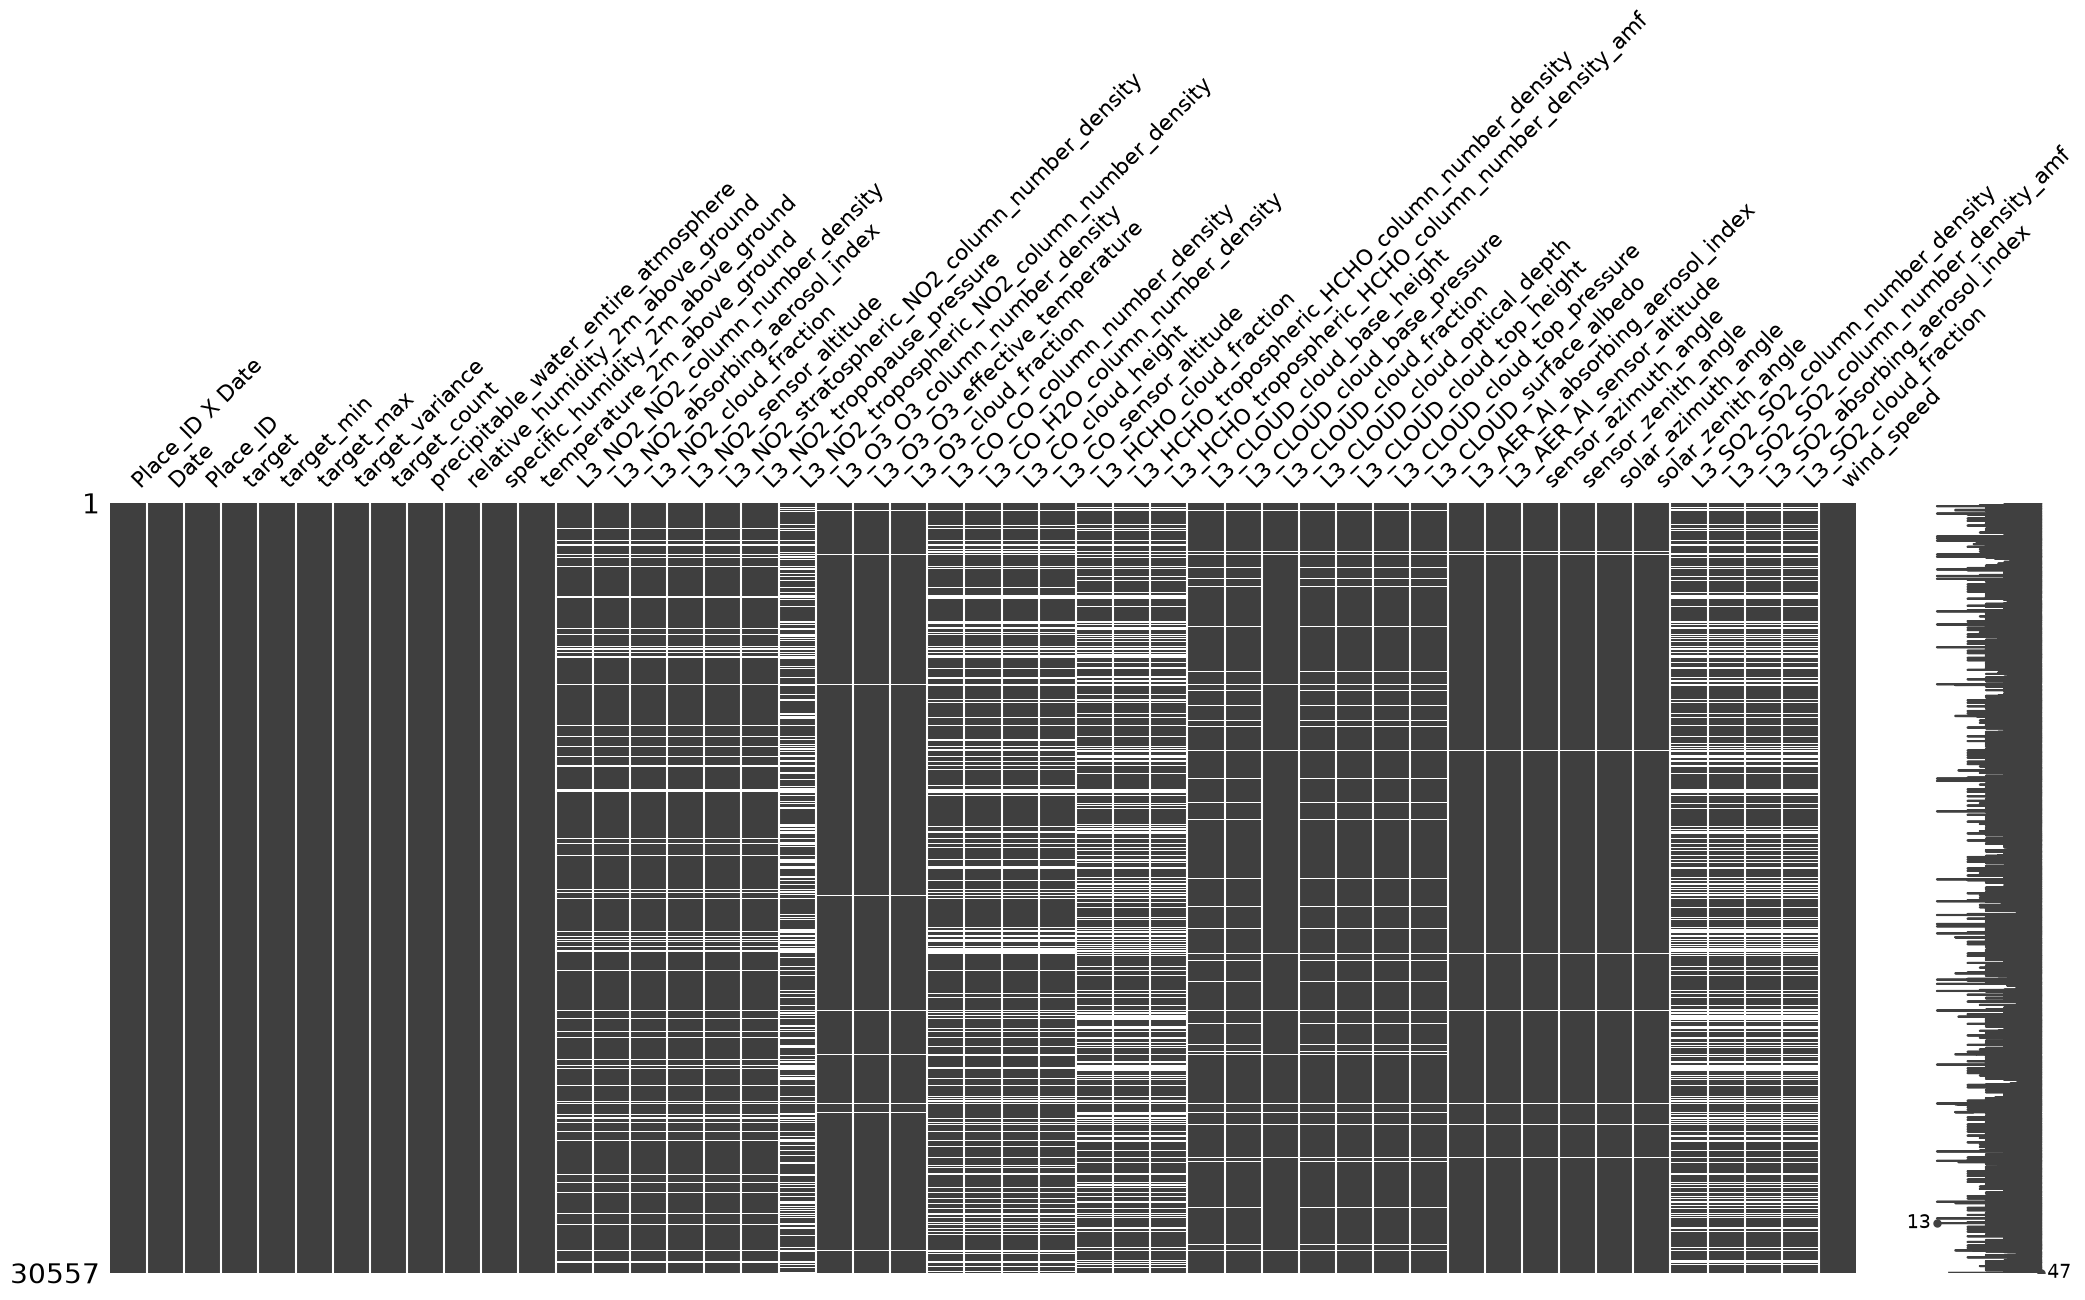

In [52]:
msno.matrix(df_clean)

In [53]:
df_clean["target_count"]

0        92
1        91
2        96
3        96
4        95
         ..
30552    72
30553    72
30554    72
30555    72
30556    72
Name: target_count, Length: 30557, dtype: int64

In [54]:
df_clean["target_count"].unique()

array([  92,   91,   96,   95,   94,   93,   85,   72,   90,   69,   81,
         80,   86,   70,   71,   82,   77,   73,   83,   55,   79,   23,
         24,   21,   22,   19,    9,   17,   11,   12,   20,   18,   64,
         33,   66,   58,   51,   48,   44,   39,   34,   67,   68,    7,
         32,   60,   40,   36,   52,   42,   38,   50,   26,   87,   76,
         63,   84,   74,   62,   59,   53,   75,   78,   89,   88,  120,
        119,  126,  142,  144,  143,  140,  141,   46,  134,  139,  138,
        130,  129,  128,  132,   47,   35,   28,   14,   41,   43,   37,
        186,  188,  182,  180,  162,  179,  189,  174,  163,  158,  190,
        187,  177,  168,  184,  160,  146,  176,  185,  166,  183,  191,
        101,  157,  171,  192,  149,  135,  175,  172,  167,  548,  571,
        531,  491,  520,  578,  576,  496,  562,  585,  587,  586,  560,
        533,  444,  489,  451,  485,  452,  484,  559,  441,  433,  486,
        376,  454,  511,  572,  540,  498,  517,  5

In [55]:
# Als CSV speichern
df_clean.to_csv("data/train_clean.csv", index=False)
print("Gespeichert unter data/train_clean.csv")

Gespeichert unter data/train_clean.csv


## Imputation: zeitliche Interpolation (Luecke < 3 Tage) + Orts-Median als Fallback

Strategie:
1. Bekannte Sensorausfaelle (exakte 0 in der Hauptmessgroesse einer L3-Gruppe: NO2, O3, CO, HCHO, SO2) werden zuerst auf NaN gesetzt, damit sie nicht als echte Messwerte interpoliert/gemittelt werden (siehe Begruendung bei `df_imputed_median` weiter unten).
2. Pro Ort (`Place_ID`) zeitbasiert interpolieren (`method="time"`, respektiert echte Kalenderabstaende, auch wenn einzelne Kalendertage als ganze Zeile fehlen) - aber NUR wenn die Luecke zwischen zwei vorhandenen Messungen kleiner als 3 Tage ist (also 1-2 fehlende Tage dazwischen).
3. Alles, was danach noch fehlt (Luecke >= 3 Tage, oder Rand-Luecken vor der ersten/nach der letzten Messung eines Ortes), wird mit dem **Median dieses Ortes** aufgefuellt.
4. Letzter Rueckfall: falls eine Spalte fuer einen Ort komplett fehlt (Orts-Median selbst ist NaN), globaler Median ueber alle Orte.


In [56]:
# Gap-aware zeitliche Interpolation (nur Luecken < 3 Tage) je Ort

df_imputed_interp = df_clean.copy()
df_imputed_interp["Date"] = pd.to_datetime(df_imputed_interp["Date"])
df_imputed_interp = df_imputed_interp.sort_values(["Place_ID", "Date"]).reset_index(drop=True)

# Bekannte Sensorausfaelle: exakte 0 in der Hauptmessgroesse einer L3-Gruppe -> ganze Gruppe
# (gleiche Zeile) auf NaN setzen, da sie dann ausnahmslos ebenfalls exakt 0 sind
gas_group_main_col = {
    "L3_NO2": "L3_NO2_NO2_column_number_density",
    "L3_O3": "L3_O3_O3_column_number_density",
    "L3_CO": "L3_CO_CO_column_number_density",
    "L3_HCHO": "L3_HCHO_tropospheric_HCHO_column_number_density",
    "L3_SO2": "L3_SO2_SO2_column_number_density",
}
n_zero_rows_total = 0
for prefix, main_col in gas_group_main_col.items():
    group_cols = [c for c in df_imputed_interp.columns if c.startswith(prefix)]
    failure_mask = df_imputed_interp[main_col] == 0
    n_zero_rows_total += failure_mask.sum()
    df_imputed_interp.loc[failure_mask, group_cols] = np.nan

print(f"Als Sensorausfall markierte Zeilen (0 -> NaN), aufsummiert ueber alle Gruppen: {n_zero_rows_total}")

cols_to_impute = df_imputed_interp.columns[df_imputed_interp.isna().any()].tolist()
print(f"{len(cols_to_impute)} Spalten mit fehlenden Werten:")
print(cols_to_impute)

MAX_GAP_DAYS = 2  # "Luecke < 3 Tage" -> 1 oder 2 fehlende Tage dazwischen werden interpoliert


def interpolate_short_gaps(group_df, col, max_gap_days=MAX_GAP_DAYS):
    s = group_df.set_index("Date")[col].sort_index()

    valid_dates = s.dropna().index
    if len(valid_dates) == 0:
        return s.values  # ganze Spalte fuer diesen Ort fehlt -> Median-Fallback uebernimmt spaeter

    date_lookup = pd.Series(valid_dates, index=valid_dates)
    prev_valid = date_lookup.reindex(s.index, method="ffill")
    next_valid = date_lookup.reindex(s.index, method="bfill")
    gap_days = (next_valid - prev_valid).dt.days

    s_interp = s.interpolate(method="time", limit_area="inside")

    is_na = s.isna()
    fill_mask = is_na & prev_valid.notna() & next_valid.notna() & (gap_days <= max_gap_days)

    result = s.copy()
    result[fill_mask] = s_interp[fill_mask]
    return result.values


n_before = df_imputed_interp[cols_to_impute].isna().sum().sum()

for col in cols_to_impute:
    parts = []
    for place_id, group in df_imputed_interp.groupby("Place_ID", sort=False):
        parts.append(pd.Series(interpolate_short_gaps(group, col), index=group.index))
    df_imputed_interp[col] = pd.concat(parts).sort_index()

n_after_interp = df_imputed_interp[cols_to_impute].isna().sum().sum()
print(f"NaNs vor Interpolation (inkl. markierter Sensorausfaelle): {n_before}")
print(f"NaNs nach Interpolation (Luecken < 3 Tage gefuellt): {n_after_interp} "
      f"({(n_before - n_after_interp) / n_before:.1%} durch Interpolation gefuellt)")


Als Sensorausfall markierte Zeilen (0 -> NaN), aufsummiert ueber alle Gruppen: 4254
34 Spalten mit fehlenden Werten:
['L3_NO2_NO2_column_number_density', 'L3_NO2_absorbing_aerosol_index', 'L3_NO2_cloud_fraction', 'L3_NO2_sensor_altitude', 'L3_NO2_stratospheric_NO2_column_number_density', 'L3_NO2_tropopause_pressure', 'L3_NO2_tropospheric_NO2_column_number_density', 'L3_O3_O3_column_number_density', 'L3_O3_O3_effective_temperature', 'L3_O3_cloud_fraction', 'L3_CO_CO_column_number_density', 'L3_CO_H2O_column_number_density', 'L3_CO_cloud_height', 'L3_CO_sensor_altitude', 'L3_HCHO_cloud_fraction', 'L3_HCHO_tropospheric_HCHO_column_number_density', 'L3_HCHO_tropospheric_HCHO_column_number_density_amf', 'L3_CLOUD_cloud_base_height', 'L3_CLOUD_cloud_base_pressure', 'L3_CLOUD_cloud_fraction', 'L3_CLOUD_cloud_optical_depth', 'L3_CLOUD_cloud_top_height', 'L3_CLOUD_cloud_top_pressure', 'L3_CLOUD_surface_albedo', 'L3_AER_AI_absorbing_aerosol_index', 'L3_AER_AI_sensor_altitude', 'sensor_azimuth_an

In [57]:
# Verbleibende Luecken (>= 3 Tage, Rand-Luecken) mit Orts-Median auffuellen,
# letzter Rueckfall: globaler Median

for col in cols_to_impute:
    df_imputed_interp[col] = df_imputed_interp[col].fillna(df_imputed_interp.groupby("Place_ID")[col].transform("median"))

n_after_median = df_imputed_interp[cols_to_impute].isna().sum().sum()
print(f"NaNs nach Orts-Median-Fallback: {n_after_median}")

for col in cols_to_impute:
    df_imputed_interp[col] = df_imputed_interp[col].fillna(df_imputed_interp[col].median())

n_final = df_imputed_interp[cols_to_impute].isna().sum().sum()
print(f"NaNs final: {n_final}")

df_imputed_interp.to_csv("data/train_imputed_interp.csv", index=False)
print("Gespeichert unter data/train_imputed.csv")


NaNs nach Orts-Median-Fallback: 61
NaNs final: 0
Gespeichert unter data/train_imputed.csv


## Alternative Imputationsstrategie: reiner Orts-Median (ohne Interpolation)

Als Vergleich zu `df_imputed_interp`: hier wird jeder fehlende Wert direkt mit dem **Median des jeweiligen Ortes (`Place_ID`)** gefuellt, ohne vorherige zeitliche Interpolation. Fallback bei komplett fehlenden Orts-Spalten: globaler Median.

**Zusaetzlich:** exakte `0.000000`-Werte sind in den L3-Schadstoffgruppen (NO2, O3, CO, HCHO, SO2) kein Messwert, sondern ein Sensor-/Pipeline-Ausfall - wenn die Hauptmessgroesse einer Gruppe exakt 0 ist, sind in derselben Zeile ausnahmslos ALLE Spalten dieser Gruppe ebenfalls exakt 0 (geprueft z.B. fuer NO2: 2611 von 2611 betroffenen Zeilen). Diese Werte werden vor der Median-Imputation auf NaN gesetzt und dann wie echte fehlende Werte behandelt. `cloud_fraction` und die Winkel-Spalten sind davon ausgenommen, da 0 dort ein legitimer physikalischer Wert sein kann (z.B. klarer Himmel).


In [58]:
# Reine Orts-Median-Imputation (keine Interpolation)

df_imputed_median = df_clean.copy()

# Bekannte Sensorausfaelle: exakte 0 in der Hauptmessgroesse einer L3-Gruppe -> ganze Gruppe
# (gleiche Zeile) auf NaN setzen, da sie dann ausnahmslos ebenfalls exakt 0 sind
gas_group_main_col = {
    "L3_NO2": "L3_NO2_NO2_column_number_density",
    "L3_O3": "L3_O3_O3_column_number_density",
    "L3_CO": "L3_CO_CO_column_number_density",
    "L3_HCHO": "L3_HCHO_tropospheric_HCHO_column_number_density",
    "L3_SO2": "L3_SO2_SO2_column_number_density",
}

n_zero_rows_total = 0
for prefix, main_col in gas_group_main_col.items():
    group_cols = [c for c in df_imputed_median.columns if c.startswith(prefix)]
    failure_mask = df_imputed_median[main_col] == 0
    n_zero_rows_total += failure_mask.sum()
    df_imputed_median.loc[failure_mask, group_cols] = np.nan

print(f"Als Sensorausfall markierte Zeilen (0 -> NaN), aufsummiert ueber alle Gruppen: {n_zero_rows_total}")

cols_to_impute_median = df_imputed_median.columns[df_imputed_median.isna().any()].tolist()
n_before_median = df_imputed_median[cols_to_impute_median].isna().sum().sum()

for col in cols_to_impute_median:
    df_imputed_median[col] = df_imputed_median[col].fillna(
        df_imputed_median.groupby("Place_ID")[col].transform("median")
    )

n_after_place_median = df_imputed_median[cols_to_impute_median].isna().sum().sum()
print(f"NaNs vor Imputation (inkl. markierter Sensorausfaelle): {n_before_median}")
print(f"NaNs nach Orts-Median: {n_after_place_median}")

# Letzter Rueckfall: globaler Median (falls eine Spalte fuer einen Ort komplett fehlt)
for col in cols_to_impute_median:
    df_imputed_median[col] = df_imputed_median[col].fillna(df_imputed_median[col].median())

n_final_median = df_imputed_median[cols_to_impute_median].isna().sum().sum()
print(f"NaNs final: {n_final_median}")

df_imputed_median.to_csv("data/train_imputed_median.csv", index=False)
print("Gespeichert unter data/train_imputed_median.csv")


Als Sensorausfall markierte Zeilen (0 -> NaN), aufsummiert ueber alle Gruppen: 4254
NaNs vor Imputation (inkl. markierter Sensorausfaelle): 130194
NaNs nach Orts-Median: 61
NaNs final: 0
Gespeichert unter data/train_imputed_median.csv


<Axes: >

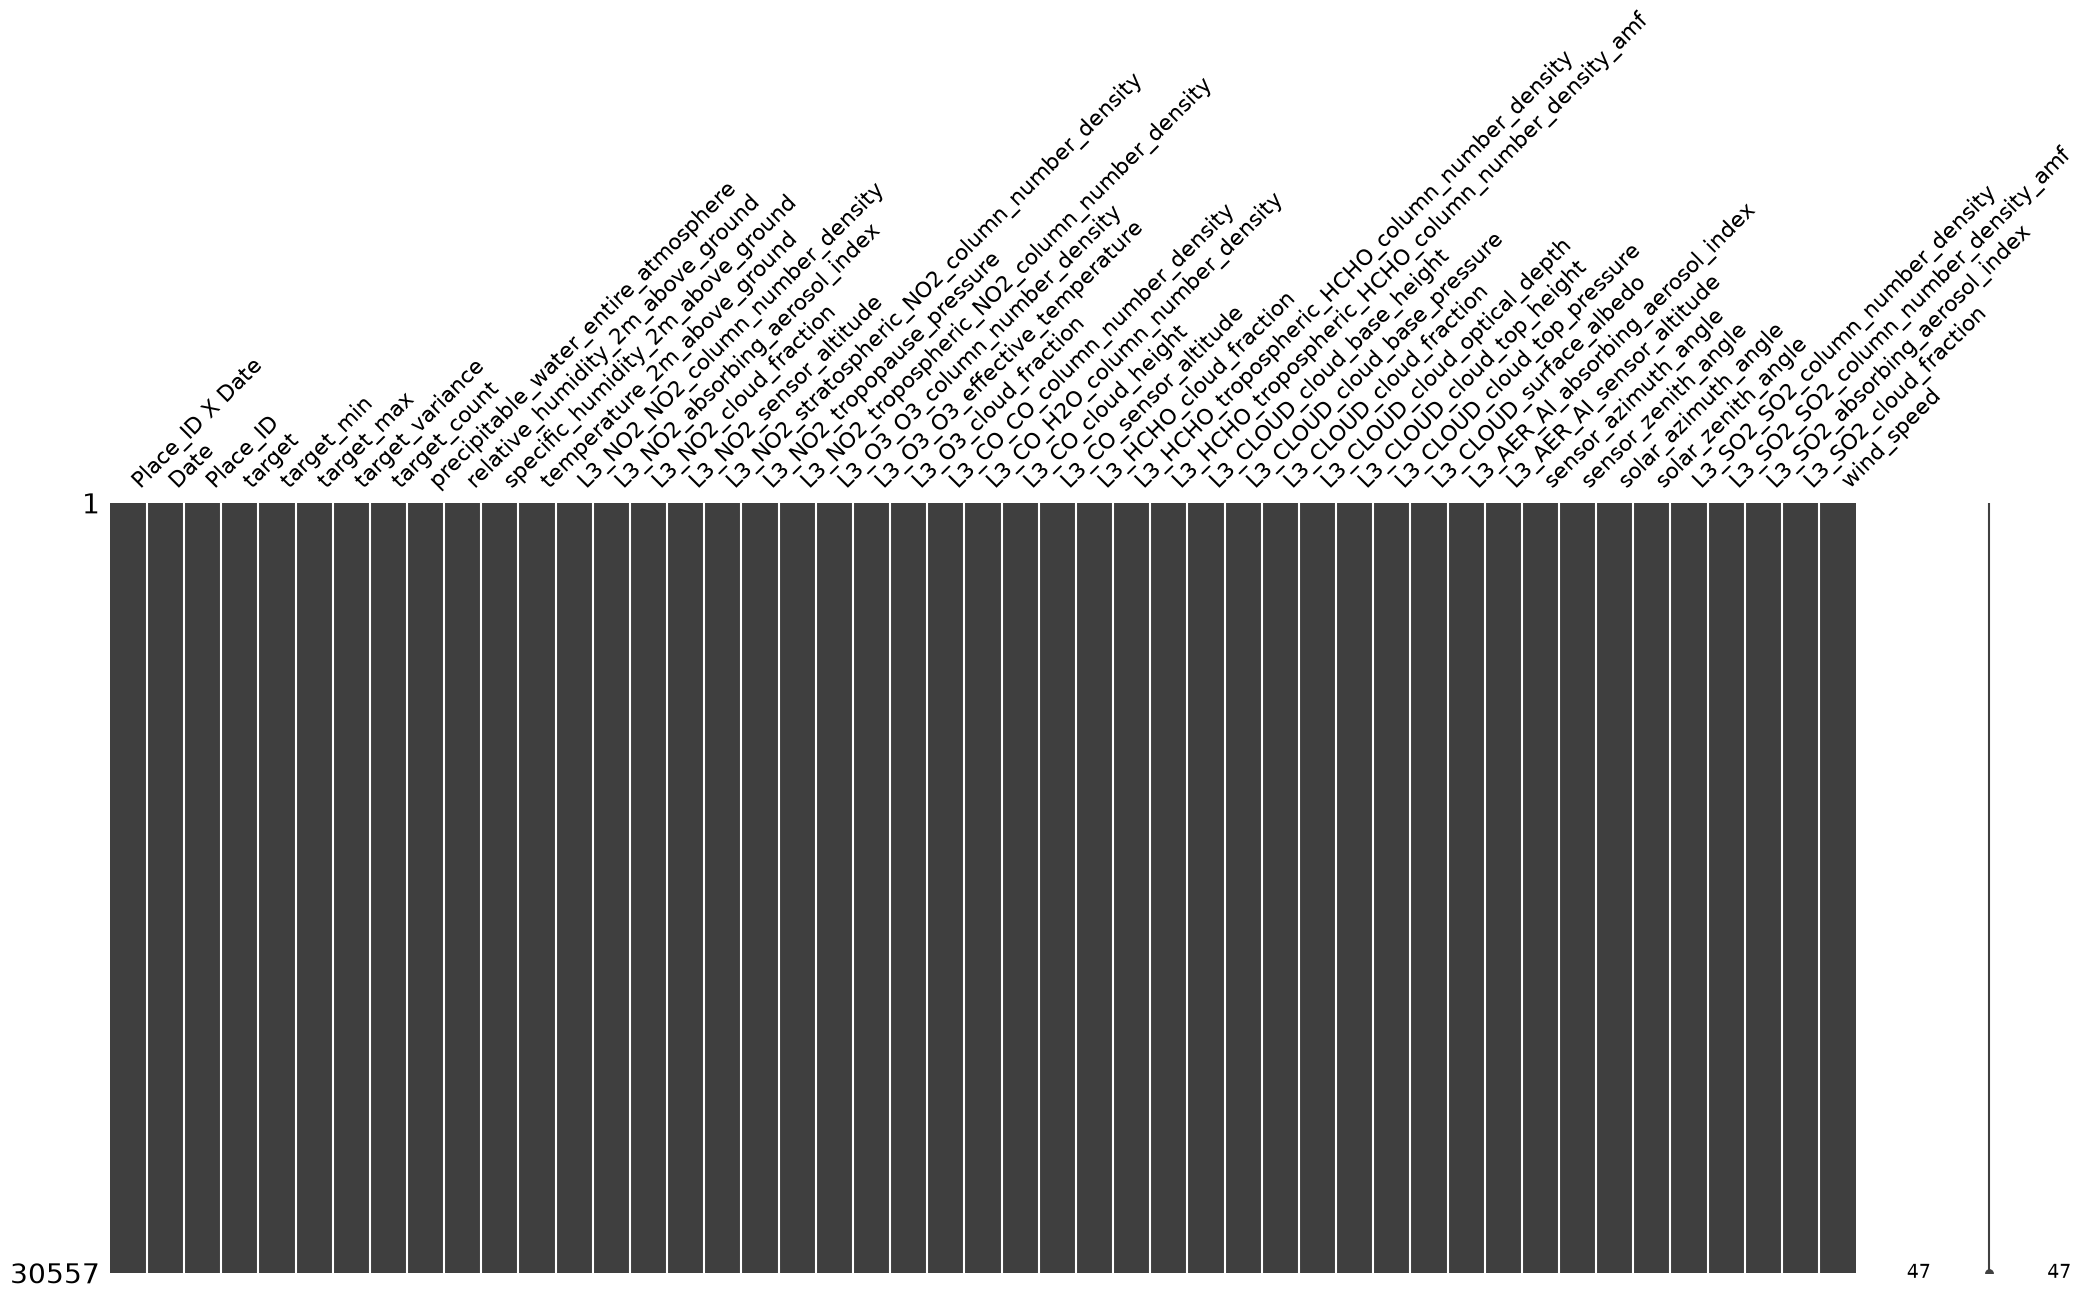

In [59]:
msno.matrix(df_imputed_median)

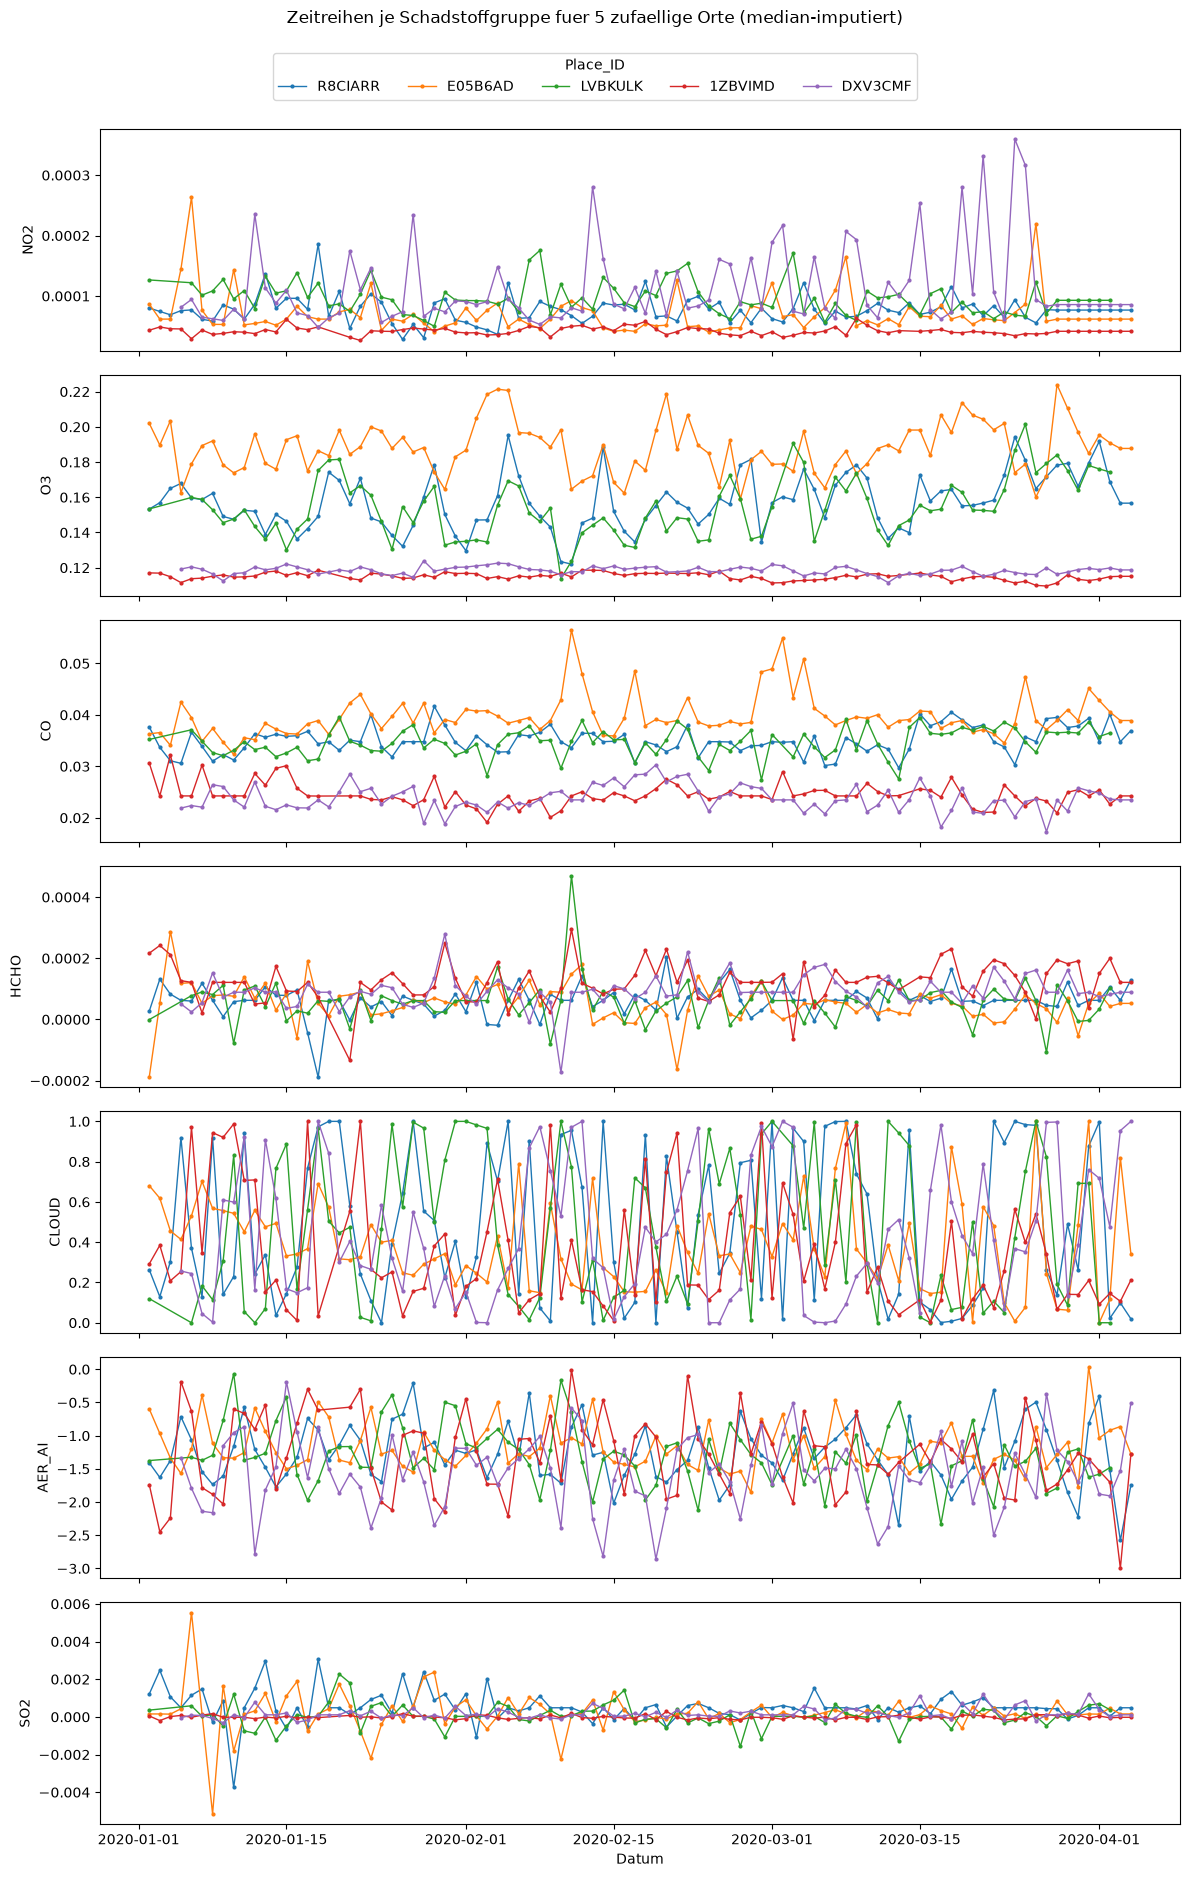

In [60]:
# Zeitreihen je Schadstoffgruppe fuer 5 zufaellige Orte (df_imputed_median, bereits median-imputiert)
# -> kein reindex auf vollstaendigen Tagesraster, da fuer manche Orte ganze Kalendertage als
#    Zeile fehlen (nicht nur NaN-Werte) - ein reindex wuerde dafuer kuenstlich neue, leere
#    Zeilen erzeugen und so faelschlich wieder Luecken zeigen, obwohl die Imputation
#    alle vorhandenen Zeilen bereits vollstaendig gefuellt hat.

gas_repr_cols = {
    "NO2": "L3_NO2_NO2_column_number_density",
    "O3": "L3_O3_O3_column_number_density",
    "CO": "L3_CO_CO_column_number_density",
    "HCHO": "L3_HCHO_tropospheric_HCHO_column_number_density",
    "CLOUD": "L3_CLOUD_cloud_fraction",
    "AER_AI": "L3_AER_AI_absorbing_aerosol_index",
    "SO2": "L3_SO2_SO2_column_number_density",
}

# 5 zufaellige Orte auswaehlen (fester Seed fuer Reproduzierbarkeit)
rng = np.random.default_rng(42)
size = 5
random_places = rng.choice(df_imputed_median["Place_ID"].unique(), size, replace=False)

palette = sns.color_palette("tab10", n_colors=len(random_places))
place_colors = dict(zip(random_places, palette))

fig, axes = plt.subplots(len(gas_repr_cols), 1, figsize=(12, 18), sharex=True)

for ax, (gas, col) in zip(axes, gas_repr_cols.items()):
    for place_id in random_places:
        df_place = df_imputed_median[df_imputed_median["Place_ID"] == place_id].copy()
        df_place["Date"] = pd.to_datetime(df_place["Date"])
        df_place = df_place.sort_values("Date")
        ax.plot(
            df_place["Date"], df_place[col],
            marker="o", markersize=2, linewidth=1,
            color=place_colors[place_id], label=place_id,
        )
    ax.set_ylabel(gas)

axes[-1].set_xlabel("Datum")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Place_ID", loc="upper center", bbox_to_anchor=(0.5, 1.02), ncol=5)
fig.suptitle("Zeitreihen je Schadstoffgruppe fuer " + str(size) + " zufaellige Orte (median-imputiert)", y=1.04)
plt.tight_layout()
plt.show()


In [63]:
# Imputation mit Median von jeweiligem Monat + Missing-Indicator-Flags
df_imputed_month_median = df_clean.copy()
df_imputed_month_median["Date"] = pd.to_datetime(df_imputed_month_median["Date"])
df_imputed_month_median["Month"] = df_imputed_month_median["Date"].dt.month

# Bekannte Sensorausfaelle (exakte 0 in der Hauptmessgroesse einer L3-Gruppe) auf NaN setzen,
# damit sie nicht als echte Messwerte in den Monats-Median einfliessen
gas_group_main_col = {
    "L3_NO2": "L3_NO2_NO2_column_number_density",
    "L3_O3": "L3_O3_O3_column_number_density",
    "L3_CO": "L3_CO_CO_column_number_density",
    "L3_HCHO": "L3_HCHO_tropospheric_HCHO_column_number_density",
    "L3_SO2": "L3_SO2_SO2_column_number_density",
}
for prefix, main_col in gas_group_main_col.items():
    group_cols = [c for c in df_imputed_month_median.columns if c.startswith(prefix)]
    failure_mask = df_imputed_month_median[main_col] == 0
    df_imputed_month_median.loc[failure_mask, group_cols] = np.nan

cols_to_impute = df_imputed_month_median.columns[df_imputed_month_median.isna().any()].tolist()
print(f"{len(cols_to_impute)} Spalten mit fehlenden Werten (inkl. markierter Sensorausfaelle)")

# Missing-Indicator-Flags VOR der Imputation anlegen, damit das Modell echte Infolage
# (z.B. Wolken-bedingte Ausfaelle) separat von den tatsaechlich gefuellten Werten sehen kann
for col in cols_to_impute:
    df_imputed_month_median[f"{col}_missing"] = df_imputed_month_median[col].isna()

n_before = df_imputed_month_median[cols_to_impute].isna().sum().sum()

# 1. Median je Ort + Monat (feinere Granularitaet als reiner Orts-Median, erfasst Saisonalitaet)
for col in cols_to_impute:
    df_imputed_month_median[col] = df_imputed_month_median[col].fillna(
        df_imputed_month_median.groupby(["Place_ID", "Month"])[col].transform("median")
    )
n_after_month = df_imputed_month_median[cols_to_impute].isna().sum().sum()

# 2. Fallback: reiner Orts-Median (falls eine Ort+Monat-Kombination komplett fehlt)
for col in cols_to_impute:
    df_imputed_month_median[col] = df_imputed_month_median[col].fillna(
        df_imputed_month_median.groupby("Place_ID")[col].transform("median")
    )
n_after_place = df_imputed_month_median[cols_to_impute].isna().sum().sum()

# 3. Letzter Rueckfall: globaler Median
for col in cols_to_impute:
    df_imputed_month_median[col] = df_imputed_month_median[col].fillna(df_imputed_month_median[col].median())
n_final = df_imputed_month_median[cols_to_impute].isna().sum().sum()

print(f"NaNs vor Imputation: {n_before}")
print(f"NaNs nach Orts+Monats-Median: {n_after_month}")
print(f"NaNs nach Orts-Median-Fallback: {n_after_place}")
print(f"NaNs final: {n_final}")

df_imputed_month_median = df_imputed_month_median.drop(columns=["Month"])
df_imputed_month_median.to_csv("data/train_imputed_month_median.csv", index=False)
print("Gespeichert unter data/train_imputed_month_median.csv")


34 Spalten mit fehlenden Werten (inkl. markierter Sensorausfaelle)
NaNs vor Imputation: 130194
NaNs nach Orts+Monats-Median: 11539
NaNs nach Orts-Median-Fallback: 61
NaNs final: 0
Gespeichert unter data/train_imputed_month_median.csv


## Baseline-Modell: Lineare Regression mit Top-Features je Imputationsstrategie

Lineares Regressions-Baseline mit den 4 am staerksten korrelierten Features (`wind_speed`, HCHO-, CO-, NO2-Column-Density, siehe 04_eda_justus.ipynb) **plus zwei weitere Features** (`L3_SO2_absorbing_aerosol_index`, r=0.152; `L3_CLOUD_cloud_fraction`, r=-0.11 als "Sichtbarkeits"-Proxy) - das sind die naechststaerksten legitimen Einzelkorrelationen nach Ausschluss von `target_min`/`target_max`/`target_variance`/`target_count` (reine Leakage-Spalten, existieren nur in `Train.csv`, nicht in `Test.csv`) und `L3_AER_AI_sensor_altitude` (Satelliten-Orbithoehe, Geometrie-Artefakt wie die Sonnenwinkel-Spalten, kein eigenstaendiger physikalischer Treiber) - **sowie zwei aus `Date` abgeleitete Zeit-Features** (`dayofyear`, `weekday`), um einen moeglichen saisonalen/woechentlichen Verlauf linear mitzunehmen (einfache ordinalen Kodierung, kein sin/cos; `Date_ordinal` war laut EDA zu schwach, siehe Checkliste). Einmal pro Imputations-Variante (`df_imputed_interp`, `df_imputed_median`, `df_imputed_month_median`), um die Strategien anhand der tatsaechlichen Modellguete zu vergleichen.

**Keine Place_ID-Zielkodierung:** Die echte `data/Test.csv` enthaelt komplett andere Orte als `Train.csv` (keine Ueberschneidung der `Place_ID`s). Ein Ortsmittelwert-Feature wuerde im internen Validierungs-Split stark helfen (dort tauchen dieselben Orte in Train und Val auf), im echten Test aber auf einen konstanten `global_mean`-Wert zusammenfallen und nichts beitragen - das haette die Generalisierungsfaehigkeit des Modells nur vorgetaeuscht, nicht verbessert.

**Split:** Ein einziger 80/20-Split (`random_state=42`) wird einmal auf den Zeilen von `Train.csv` festgelegt und fuer alle drei Imputationsvarianten identisch wiederverwendet (alle drei haben dieselbe Zeilenreihenfolge wie `df_clean`). Das Modell wird jeweils nur auf dem Train-Anteil gefittet; der Val-Anteil (= Test-Split *innerhalb* von `Train.csv`, nicht zu verwechseln mit der externen `data/Test.csv`) dient ausschliesslich der Bewertung (RMSE, R^2).


In [29]:
# Baseline: Lineare Regression mit Top-Features, je Imputationsstrategie
# Ortskodierung bewusst entfernt (siehe Markdown oben): Train.csv und die echte Test.csv
# haben komplett unterschiedliche Place_IDs, eine Zielkodierung nach Ort wuerde deshalb die
# Generalisierungsfaehigkeit nur vortaeuschen statt verbessern.
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error, r2_score

features = [
    "wind_speed",
    "L3_HCHO_tropospheric_HCHO_column_number_density",
    "L3_CO_CO_column_number_density",
    "L3_NO2_NO2_column_number_density",
    "L3_SO2_absorbing_aerosol_index",
    "L3_CLOUD_cloud_fraction",
    "dayofyear",
    "weekday",
]

# Einmaliger Split, fuer alle drei Imputationsvarianten identisch wiederverwendet (sie haben
# dieselbe Zeilenreihenfolge wie df_clean).
train_idx, val_idx = train_test_split(df_clean.index, test_size=0.2, random_state=42)

datasets = {
    "interp + Orts-Median": df_imputed_interp,
    "reiner Orts-Median": df_imputed_median,
    "Orts+Monats-Median": df_imputed_month_median,
}

# Saisonale/woechentliche Zeit-Features aus dem Datum ableiten (fuer alle drei Varianten
# identisch, da Date unveraendert aus df_clean uebernommen wurde)
for df in datasets.values():
    df["Date"] = pd.to_datetime(df["Date"])
    df["dayofyear"] = df["Date"].dt.day_of_year
    df["weekday"] = df["Date"].dt.day_of_week

results = []
for name, df in datasets.items():
    df_train_part = df.loc[train_idx]
    df_val_part = df.loc[val_idx]

    X_train = df_train_part[features]
    y_train = df_train_part["target"]
    X_val = df_val_part[features]
    y_val = df_val_part["target"]

    model = LinearRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)

    rmse = root_mean_squared_error(y_val, y_pred)
    r2 = r2_score(y_val, y_pred)
    results.append({"Imputationsstrategie": name, "RMSE": rmse, "R2": r2})

results_df = pd.DataFrame(results)
results_df


,Imputationsstrategie,RMSE,R2
0,interp + Orts-Median,37.933424,0.345965
1,reiner Orts-Median,37.940222,0.345731
2,Orts+Monats-Median,37.952315,0.345313


## Naiver Sanity-Check-Baseline: reiner Orts-Mittelwert (ohne Pollutant-Features)

Vorhersage = Out-of-Fold-Orts-Mittelwert des Targets, komplett ohne die Satelliten-/Wetter-Features. Zeigt, wie viel allein die Ortskenntnis erklaert, und damit, wie viel die vier Pollutant-Features im Modell oben tatsaechlich zusaetzlich beitragen.


In [27]:
# Naiver Baseline: Vorhersage = Orts-Mittelwert des Targets (kein Modell-Fit, keine Features)
#
# Nur einmal berechnet (nicht pro Imputationsstrategie): target und Place_ID werden von keiner
# der drei Imputationsstrategien veraendert (die betreffen nur die Pollutant-/Wetterspalten),
# daher waere das Ergebnis fuer df_imputed_interp/df_imputed_median/df_imputed_month_median
# ohnehin identisch. df_clean (vor jeglicher Imputation) reicht hier aus.

df_train_part, df_val_part = train_test_split(df_clean, test_size=0.2, random_state=42)
_, place_enc_val = add_place_target_encoding(df_train_part, df_val_part)

y_val = df_val_part["target"]
y_pred_naive = place_enc_val  # Vorhersage = Orts-Mittelwert, kein model.fit()/predict() noetig

rmse_naive = root_mean_squared_error(y_val, y_pred_naive)
r2_naive = r2_score(y_val, y_pred_naive)

print(f"Naiver Orts-Mittelwert-Baseline: RMSE = {rmse_naive:.2f}, R2 = {r2_naive:.3f}")


Naiver Orts-Mittelwert-Baseline: RMSE = 29.74, R2 = 0.598


In [37]:
# Für weitere Orte Train/Test split nach Orten. Also Orte sollen komplett im Test oder im Traindatensatz landen. 
from sklearn.model_selection import GroupShuffleSplit

df = df_imputed_interp  # gewaehlte Imputationsstrategie

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, val_idx = next(gss.split(df, groups=df["Place_ID"]))

df_train_part = df.iloc[train_idx]
df_val_part = df.iloc[val_idx]

X_train, y_train = df_train_part[features], df_train_part["target"]
X_val, y_val = df_val_part[features], df_val_part["target"]







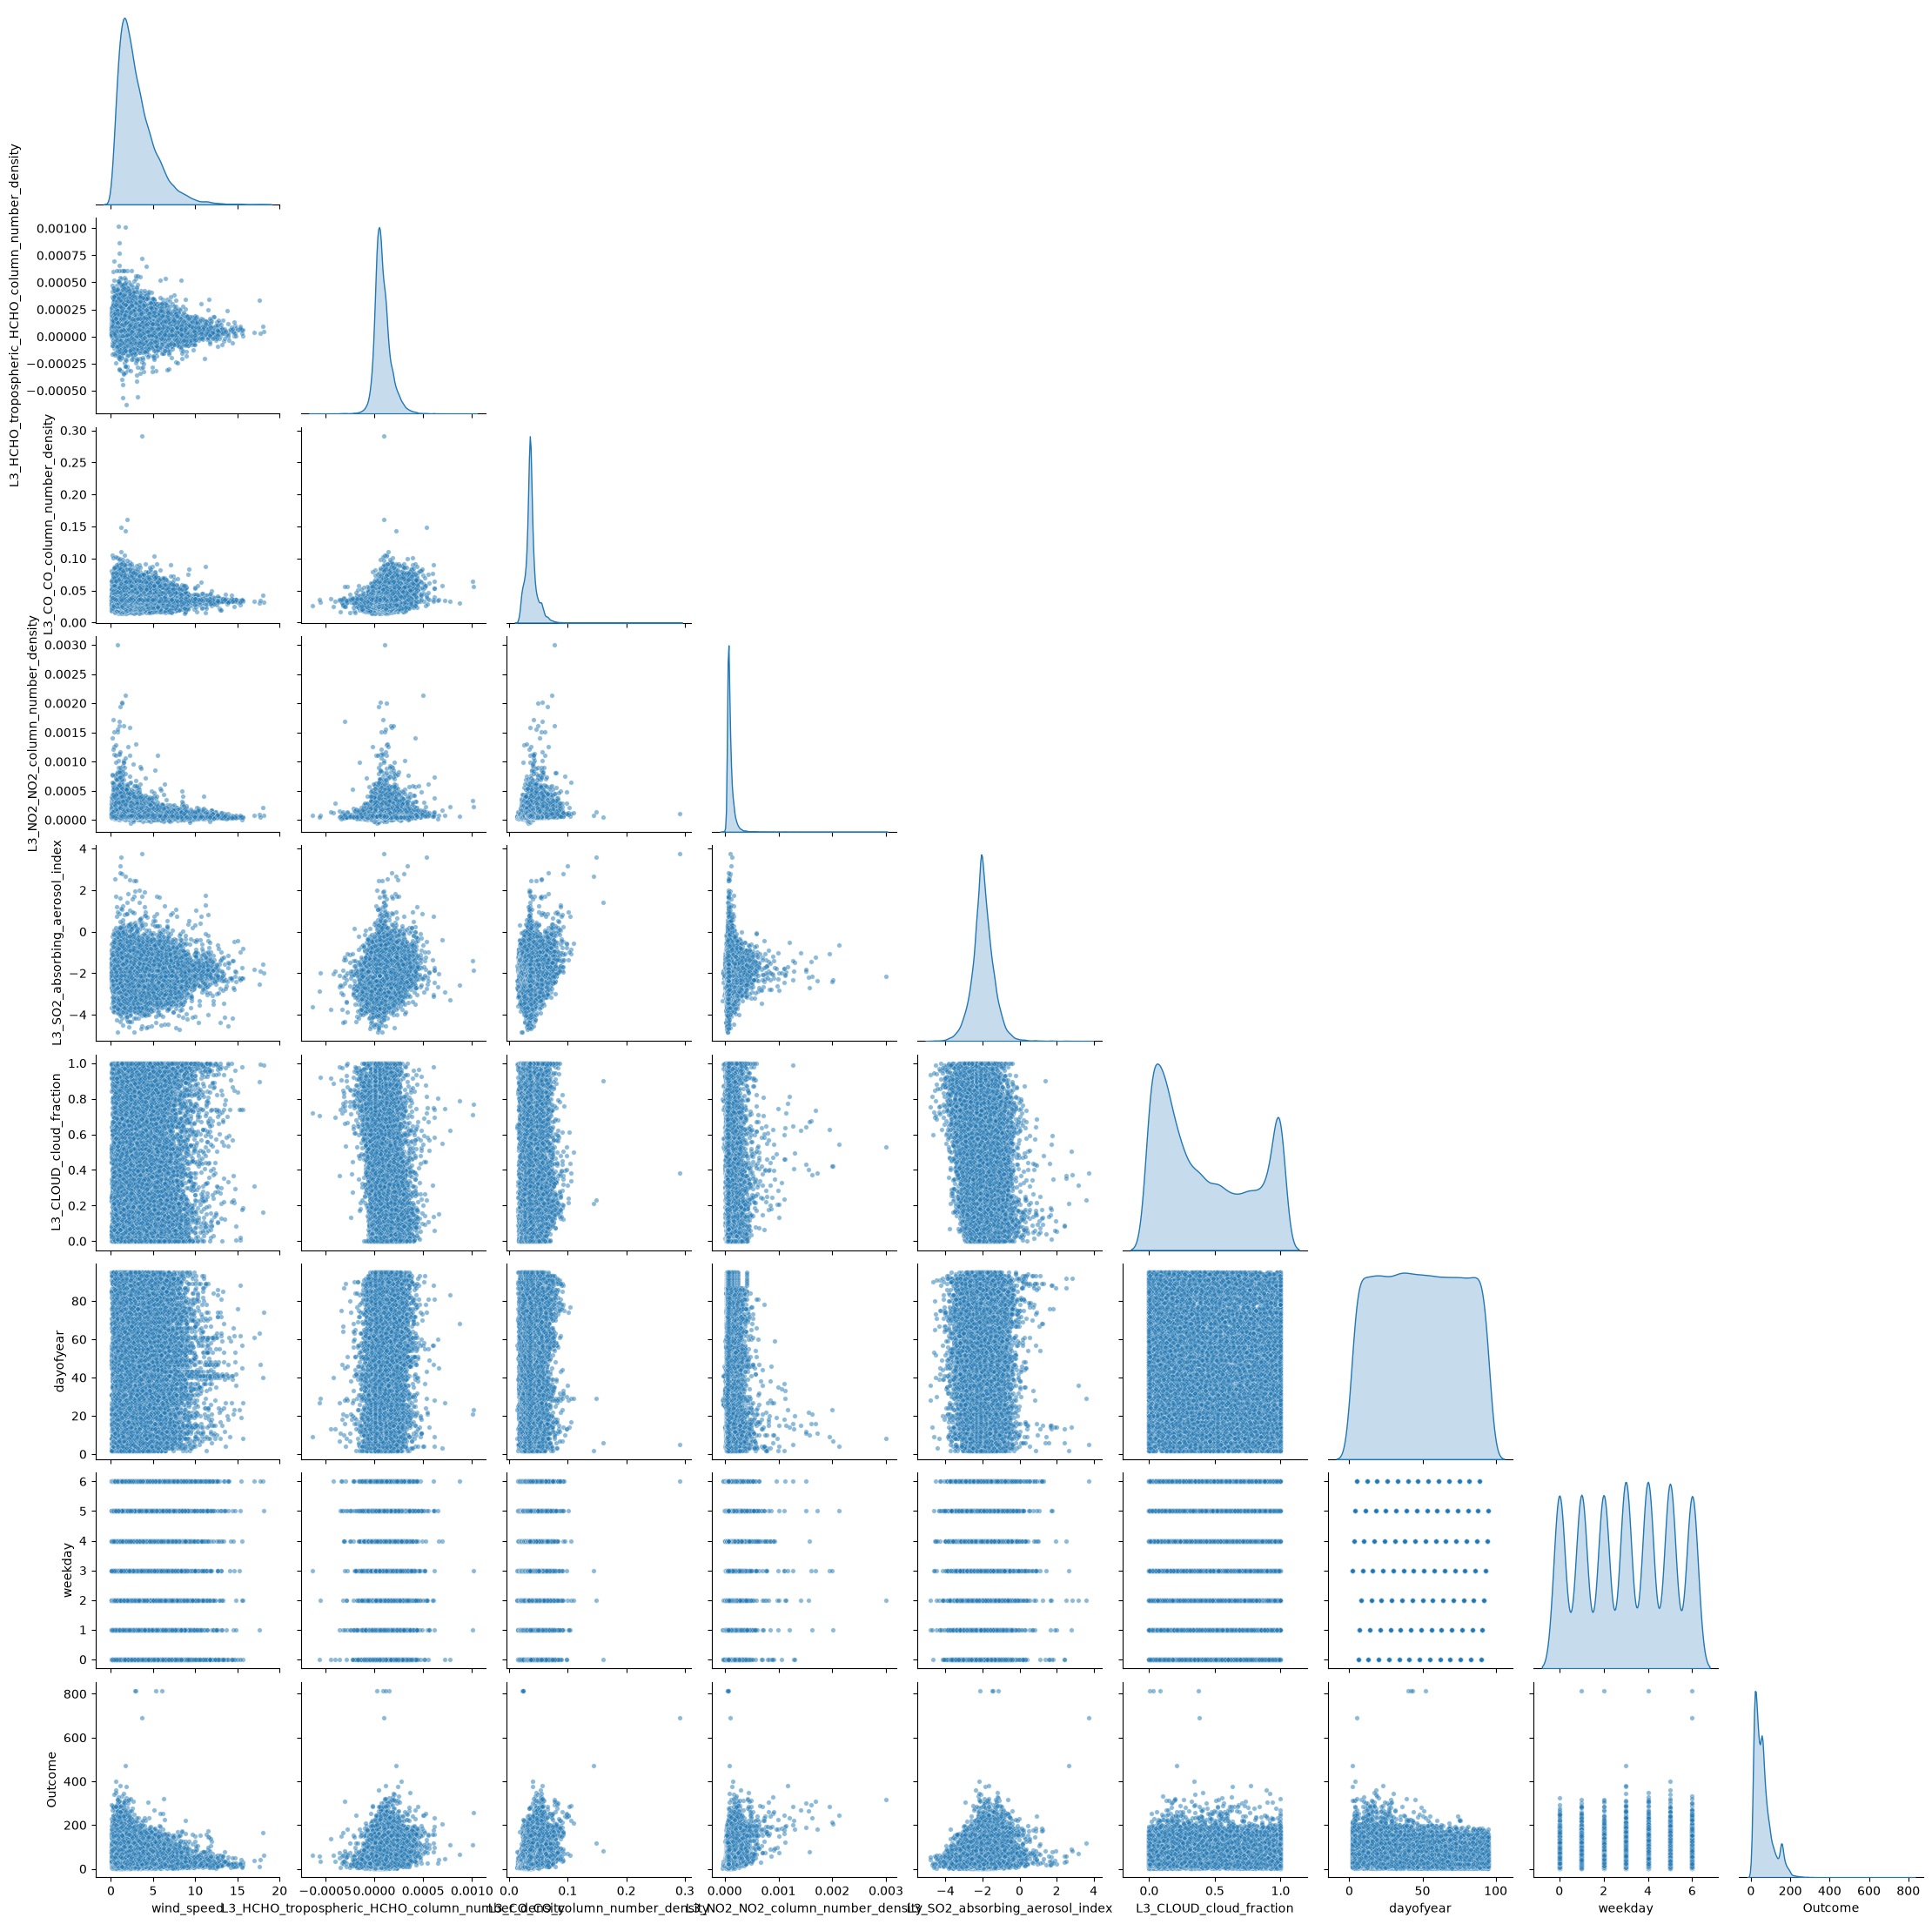

In [38]:
# Pairplot: Verteilungen und Zusammenhänge der Merkmale, Farbe = Outcome
plot_df = X_train.assign(Outcome=y_train)

sns.pairplot(
    plot_df,
    diag_kind="kde",
    corner=True,
    plot_kws={"alpha": 0.5, "s": 15},
)
plt.show()

## Wiederverwendbare Datenvorbereitung fuer das Ausprobieren verschiedener Modelle

`clean_and_impute()` fasst Reinigung (siehe `df_clean` oben) und alle drei Imputationsstrategien in einer Funktion zusammen. Geprueft: liefert fuer `strategy="interp"`, `"median"` und `"month_median"` exakt dieselben Werte wie die einzelnen Zellen weiter oben (`train_imputed_interp/median/month_median.csv`).

**Warum eine Funktion und keine Pipeline fuer Reinigung/Imputation:** Interpolation und Median-Fallback arbeiten ausschliesslich pro Ort (`Place_ID`) - es gibt keinen "gelernten Zustand", der sich auf neue, unbekannte Orte uebertragen liesse (anders als z.B. ein Scaler). Deshalb reicht eine normale Funktion, die man unveraendert auf `Train.csv` **und** spaeter auf `Test.csv` anwenden kann - es muss nichts "gefittet" werden.

**Warum Skalierung + Modell in einer `Pipeline`:** Hier gilt das Gegenteil - der `StandardScaler` muss auf den Trainingsdaten gefittet und dann unveraendert (mit denselben gelernten Mittelwerten/Standardabweichungen) auf Validierung/Test angewendet werden, um Leakage zu vermeiden. Das ist genau der Anwendungsfall, fuer den sklearn-`Pipeline`s gemacht sind.

**Features:** Zunaechst werden *alle* verbleibenden Spalten als Features verwendet (nicht nur die zuvor handverlesenen Top-Korrelationen) - nur ID-/Datums-Spalten und die `target_*`-Leakage-Spalten werden ausgeschlossen. So kann die Modellwahl (z.B. Ridge/Lasso mit eingebauter Regularisierung oder ein Tree-basiertes Modell) selbst entscheiden, welche Features nuetzlich sind, statt das per Hand vorab einzuschraenken.

Modell (`LinearRegression`) und Imputationsstrategie (`strategy=...`) lassen sich unten einfach austauschen, um verschiedene Ansaetze zu vergleichen.


## Zusaetzliches Feature-Engineering (physikalisch motiviert)

Elf weitere Features auf Basis des bereits bereinigten+imputierten DataFrames:

1. **Wolkendicke** (`cloud_thickness`): `cloud_top_height - cloud_base_height`
2. **Wolkengewichtete Saeulendichte** je Gasgruppe: `density * (1 - cloud_fraction)` - CO hat keine eigene `cloud_fraction`-Spalte, deshalb Fallback auf die allgemeine `L3_CLOUD_cloud_fraction`.
3. **Druckdifferenz durch Wolken** (`cloud_pressure_diff`): `cloud_base_pressure - cloud_top_pressure`
4. **Troposphaerischer NO2-Anteil** (`no2_tropospheric_fraction`): troposphaerische durch Gesamt-Saeule
5. **Verbrennungs-Indikatoren**: `co_no2_ratio`, `hcho_no2_ratio`
6. **Aerosol-Index-Differenzen** zwischen den drei Gruppen (`aai_diff_*`) - Hinweis: alle drei stammen aus demselben UV-Retrieval-Prinzip, Unterschiede koennten auch Retrieval-Rauschen statt echter Aerosol-Typ-Information (Rauch/Russ vs. Staub) widerspiegeln.
7. **Windwinkel** (`wind_direction`, `arctan2(v, u)`, Radiant) - direkt in `clean_and_impute()` ergaenzt, da `u`/`v` dort nach der Windgeschwindigkeits-Berechnung gedroppt werden.
8. **Ventilationsfaktor** (`ventilation_factor`): `NO2_density / (wind_speed + 0.1)`
9. **Feuchte-Interaktion** (`humidity_moisture_interaction`): `relative_humidity * precipitable_water` - **kein echter Taupunkt** (der braucht Temperatur + rel. Feuchte ueber die Magnus-Formel, nicht `precipitable_water`), hier bewusst als einfacher Interaktionsterm benannt.
10. **Winkeldifferenz Satellit-Sonne** (`sun_sensor_azimuth_diff`) - ohne zirkulare Normierung (z.B. ergeben 350° vs. 10° hier 340° statt 20°).
11. **Kosinus-Transformation der Zenit-Winkel** (`cos_solar_zenith`, `cos_sensor_zenith`) - physikalisch der Airmass-/Pfadlaengen-Faktor.

**Wichtiger Befund beim Testen:** Die Verhaeltnis-Features (4, 5) koennen extreme Ausreisser produzieren (`co_no2_ratio` bis ~3.7 Mio.), weil `L3_NO2_tropospheric_NO2_column_number_density` vereinzelt nahe 0 oder sogar leicht negativ wird (Retrieval-Rauschen nahe der Nachweisgrenze). Die kleine Konstante im Nenner (1e-6) verhindert nur eine Division durch exakt 0, nicht die Instabilitaet nahe 0 selbst - ggf. spaeter mit Clipping (z.B. 1./99. Perzentil) nachbessern.


In [ ]:
# Engineering der 11 zusaetzlichen, physikalisch motivierten Features (siehe Markdown oben)
GAS_GROUP_CLOUD_COL = {
    "L3_NO2": "L3_NO2_cloud_fraction",
    "L3_O3": "L3_O3_cloud_fraction",
    "L3_HCHO": "L3_HCHO_cloud_fraction",
    "L3_SO2": "L3_SO2_cloud_fraction",
    # L3_CO hat keine eigene cloud_fraction-Spalte -> Fallback auf die allgemeine L3_CLOUD-Gruppe
    "L3_CO": "L3_CLOUD_cloud_fraction",
}

EPS = 1e-6  # verhindert Division durch exakt 0 bei den Verhaeltnis-Features (4, 5)


def engineer_features(df):
    """Zusaetzliche Features auf Basis des bereits bereinigten+imputierten DataFrames
    (Ausgabe von clean_and_impute())."""
    df = df.copy()

    # 1. Wolkendicke (vertikale Ausdehnung)
    df["cloud_thickness"] = df["L3_CLOUD_cloud_top_height"] - df["L3_CLOUD_cloud_base_height"]

    # 2. Wolkengewichtete Saeulendichte je Gasgruppe (Saeule * sichtbarer Anteil)
    for prefix, main_col in GAS_GROUP_MAIN_COL.items():
        cloud_col = GAS_GROUP_CLOUD_COL[prefix]
        df[f"{prefix}_cloud_weighted_density"] = df[main_col] * (1 - df[cloud_col])

    # 3. Druckdifferenz durch Wolken
    df["cloud_pressure_diff"] = df["L3_CLOUD_cloud_base_pressure"] - df["L3_CLOUD_cloud_top_pressure"]

    # 4. Troposphaerischer NO2-Anteil
    df["no2_tropospheric_fraction"] = (
        df["L3_NO2_tropospheric_NO2_column_number_density"] / (df["L3_NO2_NO2_column_number_density"] + EPS)
    )

    # 5. Verbrennungs-Indikatoren
    df["co_no2_ratio"] = (
        df["L3_CO_CO_column_number_density"] / (df["L3_NO2_tropospheric_NO2_column_number_density"] + EPS)
    )
    df["hcho_no2_ratio"] = (
        df["L3_HCHO_tropospheric_HCHO_column_number_density"] / (df["L3_NO2_NO2_column_number_density"] + EPS)
    )

    # 6. Aerosol-Index-Differenzen (Rauch/Russ vs. Staub-Hinweis, siehe Caveat im Markdown)
    df["aai_diff_aer_so2"] = df["L3_AER_AI_absorbing_aerosol_index"] - df["L3_SO2_absorbing_aerosol_index"]
    df["aai_diff_aer_no2"] = df["L3_AER_AI_absorbing_aerosol_index"] - df["L3_NO2_absorbing_aerosol_index"]
    df["aai_diff_so2_no2"] = df["L3_SO2_absorbing_aerosol_index"] - df["L3_NO2_absorbing_aerosol_index"]

    # 7. Windwinkel -> bereits in clean_and_impute() als "wind_direction" berechnet

    # 8. Ventilationsfaktor
    df["ventilation_factor"] = df["L3_NO2_NO2_column_number_density"] / (df["wind_speed"] + 0.1)

    # 9. Feuchte-Interaktion (kein echter Taupunkt, siehe Markdown)
    df["humidity_moisture_interaction"] = (
        df["relative_humidity_2m_above_ground"] * df["precipitable_water_entire_atmosphere"]
    )

    # 10. Winkeldifferenz Satellit-Sonne (ohne zirkulare Normierung, siehe Markdown)
    df["sun_sensor_azimuth_diff"] = (df["solar_azimuth_angle"] - df["sensor_azimuth_angle"]).abs()

    # 11. Kosinus-Transformation der Zenit-Winkel (Airmass-/Pfadlaengen-Proxy)
    df["cos_solar_zenith"] = np.cos(np.radians(df["solar_zenith_angle"]))
    df["cos_sensor_zenith"] = np.cos(np.radians(df["sensor_zenith_angle"]))

    return df


In [ ]:
# Wiederverwendbare Datenvorbereitung: Reinigung + Imputation als Funktion (zustandslos, pro
# Ort), Skalierung + Modell als Pipeline (muss auf Train gefittet und auf Val/Test unveraendert
# angewendet werden). Siehe Markdown oben fuer die Begruendung dieser Aufteilung.
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error, r2_score

GAS_GROUP_MAIN_COL = {
    "L3_NO2": "L3_NO2_NO2_column_number_density",
    "L3_O3": "L3_O3_O3_column_number_density",
    "L3_CO": "L3_CO_CO_column_number_density",
    "L3_HCHO": "L3_HCHO_tropospheric_HCHO_column_number_density",
    "L3_SO2": "L3_SO2_SO2_column_number_density",
}


def _basic_clean(df_raw):
    df = df_raw.copy()
    df["wind_speed"] = np.sqrt(
        df["u_component_of_wind_10m_above_ground"] ** 2
        + df["v_component_of_wind_10m_above_ground"] ** 2
    )
    # Windwinkel (Radiant) - muss vor dem Droppen von u/v berechnet werden
    df["wind_direction"] = np.arctan2(
        df["v_component_of_wind_10m_above_ground"],
        df["u_component_of_wind_10m_above_ground"],
    )
    df = df.drop(columns=[
        "u_component_of_wind_10m_above_ground",
        "v_component_of_wind_10m_above_ground",
    ])

    angle_suffixes = [
        "sensor_azimuth_angle", "sensor_zenith_angle",
        "solar_azimuth_angle", "solar_zenith_angle",
    ]
    keep_group = "L3_AER_AI"
    angle_cols_all = [c for c in df.columns if c.endswith(tuple(angle_suffixes))]
    angle_cols_keep = [f"{keep_group}_{suffix}" for suffix in angle_suffixes]
    df = df.drop(columns=[c for c in angle_cols_all if c not in angle_cols_keep])
    df = df.rename(columns={f"{keep_group}_{suffix}": suffix for suffix in angle_suffixes})

    df = df.drop(columns=[c for c in df.columns if "slant_column_number_density" in c])
    df = df.drop(columns=[c for c in df.columns if c.startswith("L3_CH4")])

    df["Date"] = pd.to_datetime(df["Date"])
    return df


def _mark_sensor_failures(df):
    for prefix, main_col in GAS_GROUP_MAIN_COL.items():
        group_cols = [c for c in df.columns if c.startswith(prefix)]
        failure_mask = df[main_col] == 0
        df.loc[failure_mask, group_cols] = np.nan
    return df


def _interpolate_short_gaps(group_df, col, max_gap_days):
    s = group_df.set_index("Date")[col].sort_index()
    valid_dates = s.dropna().index
    if len(valid_dates) == 0:
        return s.values
    date_lookup = pd.Series(valid_dates, index=valid_dates)
    prev_valid = date_lookup.reindex(s.index, method="ffill")
    next_valid = date_lookup.reindex(s.index, method="bfill")
    gap_days = (next_valid - prev_valid).dt.days
    s_interp = s.interpolate(method="time", limit_area="inside")
    is_na = s.isna()
    fill_mask = is_na & prev_valid.notna() & next_valid.notna() & (gap_days <= max_gap_days)
    result = s.copy()
    result[fill_mask] = s_interp[fill_mask]
    return result.values


def clean_and_impute(df_raw, strategy="interp", max_gap_days=2):
    """Reinigung + Imputation ab Rohdaten (Train.csv-/Test.csv-Format).
    strategy: "interp" (Zeit-Interpolation + Orts-Median-Fallback), "median" (reiner
    Orts-Median) oder "month_median" (Orts+Monats-Median + Missing-Flags).
    Arbeitet ausschliesslich pro Ort - daher unveraendert auf neue, unbekannte Orte
    (z.B. Test.csv) anwendbar, kein uebertragbarer Zustand noetig."""
    df = _basic_clean(df_raw)
    df = _mark_sensor_failures(df)

    if strategy == "interp":
        df = df.sort_values(["Place_ID", "Date"]).reset_index(drop=True)
        cols_to_impute = df.columns[df.isna().any()].tolist()
        for col in cols_to_impute:
            parts = []
            for place_id, group in df.groupby("Place_ID", sort=False):
                parts.append(pd.Series(_interpolate_short_gaps(group, col, max_gap_days), index=group.index))
            df[col] = pd.concat(parts).sort_index()
        for col in cols_to_impute:
            df[col] = df[col].fillna(df.groupby("Place_ID")[col].transform("median"))
        for col in cols_to_impute:
            df[col] = df[col].fillna(df[col].median())

    elif strategy == "median":
        cols_to_impute = df.columns[df.isna().any()].tolist()
        for col in cols_to_impute:
            df[col] = df[col].fillna(df.groupby("Place_ID")[col].transform("median"))
        for col in cols_to_impute:
            df[col] = df[col].fillna(df[col].median())

    elif strategy == "month_median":
        df["Month"] = df["Date"].dt.month
        cols_to_impute = [c for c in df.columns[df.isna().any()] if c != "Month"]
        for col in cols_to_impute:
            df[f"{col}_missing"] = df[col].isna()
        for col in cols_to_impute:
            df[col] = df[col].fillna(df.groupby(["Place_ID", "Month"])[col].transform("median"))
        for col in cols_to_impute:
            df[col] = df[col].fillna(df.groupby("Place_ID")[col].transform("median"))
        for col in cols_to_impute:
            df[col] = df[col].fillna(df[col].median())
        df = df.drop(columns=["Month"])

    else:
        raise ValueError(f"Unbekannte Strategie: {strategy}")

    df["dayofyear"] = df["Date"].dt.day_of_year
    df["weekday"] = df["Date"].dt.day_of_week
    return df


# Beispielhafte Verwendung: Daten vorbereiten, ortsbasiert splitten, Pipeline fitten
df_model_ready = engineer_features(clean_and_impute(df_train, strategy="interp"))

# Alle Spalten als Features verwenden, bis auf ID-/Datums-/Leakage-Spalten:
# - "Place_ID X Date", "Date", "Place_ID": keine direkt nutzbaren numerischen Features
#   (Place_ID wuerde ausserdem nicht auf neue Orte in Test.csv generalisieren)
# - "target_min"/"target_max"/"target_variance"/"target_count": Leakage, existieren nur in
#   Train.csv (siehe Diskussion oben)
exclude_cols = [
    "Place_ID X Date", "Date", "Place_ID",
    "target", "target_min", "target_max", "target_variance", "target_count",
]
features = [c for c in df_model_ready.columns if c not in exclude_cols]

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, val_idx = next(gss.split(df_model_ready, groups=df_model_ready["Place_ID"]))

df_train_part = df_model_ready.iloc[train_idx]
df_val_part = df_model_ready.iloc[val_idx]

X_train, y_train = df_train_part[features], df_train_part["target"]
X_val, y_val = df_val_part[features], df_val_part["target"]

# Modell hier einfach austauschbar (z.B. Ridge, HistGradientBoostingRegressor, ...)
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression()),
])
pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_val)

rmse = root_mean_squared_error(y_val, y_pred)
r2 = r2_score(y_val, y_pred)
print(f"RMSE = {rmse:.2f}, R2 = {r2:.3f}")


## Modell B: Ridge-Regression mit Polynomial-/Interaktions-Features

Statt eines Tree-Modells bleibt dieser Ansatz in der linearen Regressions-Familie, erweitert die Top-Features aber um **quadratische Terme** (`x^2`) und **paarweise Wechselwirkungen** (`x_i * x_j`, z.B. `wind_speed * L3_CO_...`) via `PolynomialFeatures`. Damit kann das Modell gezielt die Hypothese "Wind moduliert den Effekt der Gas-Dichte" abbilden, die eine reine lineare Regression nicht erfassen kann.

Bewusst nur auf den 8 Top-Features (nicht allen 41) angewendet - sonst wuerden bei `degree=2` ueber 900 Spalten entstehen (alle Paare). Wegen der dadurch entstehenden Multikollinearitaet wird `Ridge` statt `LinearRegression` verwendet.

**Hyperparameter-Tuning per Kreuzvalidierung:**
- `model__alpha` (Ridge-Regularisierungsstaerke) - der wichtigste Hebel, mehrere Groessenordnungen durchprobiert.
- `poly__degree` (1 = keine Interaktionen/Quadrate vs. 2 = quadratisch + Wechselwirkungen).

Wichtig: `GroupKFold` statt normalem `KFold` - auch waehrend der Kreuzvalidierung sollen ganze Orte zusammenbleiben, damit jede CV-Faltung weiterhin "komplett neue Orte" simuliert (dieselbe Logik wie beim aeusseren `GroupShuffleSplit` oben).


### Erklaerung: `top15_features` (die 15 Features in Modell B)

**Schadstoff-Saeulendichten** (Einheit: mol/m², vertikal integriert von der Erdoberflaeche bis zum Satelliten bzw. bis zur Tropopause - **keine** bodennahe Volumenkonzentration wie `target`, sondern die Gesamtmenge des Gases in einer gedachten Luftsaeule ueber dem Ort; siehe Diskussion weiter oben zum Unterschied Saeule vs. Bodenkonzentration):
- **`L3_CO_CO_column_number_density`**: Kohlenmonoxid-Saeule - klassischer Verbrennungs-Tracer (Verkehr, Biomasseverbrennung).
- **`L3_HCHO_tropospheric_HCHO_column_number_density`**: Formaldehyd-Saeule, nur troposphaerischer Anteil - Tracer fuer VOC-Emissionen (Biomasseverbrennung, Vegetation, Industrie).
- **`L3_NO2_NO2_column_number_density`**: NO2-Gesamtsaeule (Troposphaere + Stratosphaere) - Verbrennungs-Tracer.
- **`L3_NO2_tropospheric_NO2_column_number_density`**: wie oben, aber nur der troposphaerische Anteil (naeher am Boden, relevanter fuer lokale Emissionen als die Gesamtsaeule).
- **`L3_O3_O3_column_number_density`**: Ozon-Gesamtsaeule - zu grossen Teilen stratosphaerisch (Ozonschicht), daher schwaecherer direkter Bezug zu bodennaher Luftqualitaet.

**Aerosol-Index:**
- **`L3_SO2_absorbing_aerosol_index`**: UV Aerosol Index (dimensionslos, **keine** Konzentration) aus der SO2-Retrieval-Gruppe - misst, wie stark UV-Licht von Partikeln absorbiert wird (positive Werte: Rauch/Staub vorhanden). Trotz des Namens keine SO2-Messung selbst.

**Wind:**
- **`wind_speed`**: `sqrt(u² + v²)` aus den Wetter-Reanalyse-Windkomponenten (u = Ost-West, v = Nord-Sued) in 10m Hoehe, Einheit m/s - physikalische Groesse, direkt nutzbar.

**Wolken-/Sichtbarkeits-Parameter** (beschreiben den Atmosphaerenzustand zum Zeitpunkt der Messung, keine Schadstoffe selbst - koennen aber sowohl ueber reale Durchmischungseffekte als auch ueber Mess-Artefakte/Saisonalitaet mit `target` korrelieren, siehe Diskussion weiter oben):
- **`L3_NO2_cloud_fraction`**, **`L3_O3_cloud_fraction`**, **`L3_CLOUD_cloud_fraction`**: Anteil des Satelliten-Pixels, der von Wolken bedeckt ist (0-1), aus drei verschiedenen Retrieval-Gruppen (NO2, O3, dediziertes CLOUD-Produkt).
- **`L3_CLOUD_cloud_top_pressure`**, **`L3_CLOUD_cloud_base_pressure`**: Luftdruck (hPa) an Ober-/Unterkante der erkannten Wolkenschicht (niedrigerer Druck = groessere Hoehe).
- **`L3_CLOUD_cloud_top_height`**: Hoehe (m) der Wolkenoberkante.
- **`L3_CO_cloud_height`**: Wolkenhoehen-Schaetzung, die innerhalb des CO-Retrieval-Algorithmus als Hilfsgroesse verwendet wird (kein eigenstaendiges Schadstoff-Signal).
- **`L3_CLOUD_cloud_optical_depth`**: optische Dicke der Wolke (dimensionslos) - wie stark Licht beim Durchqueren der Wolke abgeschwaecht wird; hoehere Werte = dichtere/dickere Wolken.


In [61]:
# Modell B: Ridge-Regression mit Polynomial-/Interaktions-Features, Hyperparameter per
# GroupKFold-Kreuzvalidierung optimiert (siehe Markdown oben fuer die Begruendung).
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupKFold, GridSearchCV

top15_features = [
    "L3_CO_CO_column_number_density",
    "L3_HCHO_tropospheric_HCHO_column_number_density",
    "wind_speed",
    "L3_NO2_NO2_column_number_density",
    "L3_NO2_tropospheric_NO2_column_number_density",
    "L3_SO2_absorbing_aerosol_index",
    "L3_NO2_cloud_fraction",
    "L3_CLOUD_cloud_top_pressure",
    "L3_CLOUD_cloud_optical_depth",
    "L3_CLOUD_cloud_fraction",
    "L3_O3_cloud_fraction",
    "L3_CLOUD_cloud_top_height",
    "L3_CO_cloud_height",
    "L3_CLOUD_cloud_base_pressure",
    "L3_O3_O3_column_number_density",
]

X_train_poly = df_train_part[top15_features]
X_val_poly = df_val_part[top15_features]

pipe_poly = Pipeline([
    ("poly", PolynomialFeatures(include_bias=False)),
    ("scaler", StandardScaler()),
    ("model", Ridge()),
])

# Zu optimierende Hyperparameter: Regularisierungsstaerke (alpha) und Grad der
# Polynomial-Erweiterung (1 = aus, 2 = quadratisch + Wechselwirkungen)
param_grid = {
    "poly__degree": [1, 2, 3],
    "model__alpha": [500, 1000, 1500]
}

group_kfold = GroupKFold(n_splits=5)
grid = GridSearchCV(
    pipe_poly,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=group_kfold,
    n_jobs=-1,
)
grid.fit(X_train_poly, y_train, groups=df_train_part["Place_ID"])

print("Beste Hyperparameter:", grid.best_params_)

best_pipe = grid.best_estimator_
y_pred_poly = best_pipe.predict(X_val_poly)

rmse_poly = root_mean_squared_error(y_val, y_pred_poly)
r2_poly = r2_score(y_val, y_pred_poly)
print(f"RMSE = {rmse_poly:.2f}, R2 = {r2_poly:.3f}")


Beste Hyperparameter: {'model__alpha': 1500, 'poly__degree': 2}
RMSE = 33.79, R2 = 0.349


## Modell B (erweitert): Ridge-Regression mit Polynomial-Features + neuen Engineering-Features

Dieselbe Pipeline wie bei Modell B oben (`PolynomialFeatures` + `Ridge`, Hyperparameter per `GroupKFold`-Kreuzvalidierung), aber die Feature-Liste wird um eine Auswahl der neuen, oben konstruierten Features erweitert: `ventilation_factor`, `wind_direction`, `no2_tropospheric_fraction`, `co_no2_ratio`, `hcho_no2_ratio`, `cloud_thickness`, `cloud_pressure_diff`, `humidity_moisture_interaction`, `aai_diff_aer_so2`.

**Bewusst nicht alle 19 neuen Features** (z.B. nicht alle 5 wolkengewichteten Dichten oder alle 3 Aerosol-Index-Differenzen) - bei `degree=2` waechst die Anzahl der Polynomterme quadratisch mit der Feature-Anzahl, und viele der ausgelassenen Features sind ohnehin Kombinationen von Spalten, die schon einzeln in der Liste stehen (z.B. waere `L3_NO2_cloud_weighted_density` redundant zu `L3_NO2_NO2_...` + `L3_NO2_cloud_fraction`, deren Produkt `PolynomialFeatures` bei `degree=2` ohnehin automatisch erzeugt).

`poly__degree` wird hier nur auf `[1, 2]` getestet (nicht bis 4 wie zuvor) - bei 24 Features waere `degree=4` mit ueber 20.000 Polynomtermen praktisch nicht mehr in angemessener Zeit rechenbar.


In [ ]:
# Modell B (erweitert): Ridge + Polynomial-Features inkl. neuer Engineering-Features
extended_features = top15_features + [
    "ventilation_factor",
    "wind_direction",
    "no2_tropospheric_fraction",
    "co_no2_ratio",
    "hcho_no2_ratio",
    "cloud_thickness",
    "cloud_pressure_diff",
    "humidity_moisture_interaction",
    "aai_diff_aer_so2",
]

X_train_ext = df_train_part[extended_features]
X_val_ext = df_val_part[extended_features]

pipe_poly_ext = Pipeline([
    ("poly", PolynomialFeatures(include_bias=False)),
    ("scaler", StandardScaler()),
    ("model", Ridge()),
])

param_grid_ext = {
    "poly__degree": [1, 2],
    "model__alpha": [0.1, 1.0, 10.0, 100.0, 1000.0],
}

group_kfold_ext = GroupKFold(n_splits=5)
grid_ext = GridSearchCV(
    pipe_poly_ext,
    param_grid=param_grid_ext,
    scoring="neg_root_mean_squared_error",
    cv=group_kfold_ext,
    n_jobs=-1,
)
grid_ext.fit(X_train_ext, y_train, groups=df_train_part["Place_ID"])

print("Beste Hyperparameter:", grid_ext.best_params_)

best_pipe_ext = grid_ext.best_estimator_
y_pred_ext = best_pipe_ext.predict(X_val_ext)

rmse_ext = root_mean_squared_error(y_val, y_pred_ext)
r2_ext = r2_score(y_val, y_pred_ext)
print(f"RMSE = {rmse_ext:.2f}, R2 = {r2_ext:.3f}")


## Modell C: Hist Gradient Boosting Regressor (reduzierte Features + Orts-Kontext)

Statt `GradientBoostingRegressor` jetzt `HistGradientBoostingRegressor` - histogrammbasiert, deutlich schneller (Sekunden statt Minuten pro Fit), und mit **eingebautem Early Stopping** (`early_stopping="auto"`, bei >10.000 Zeilen automatisch aktiv): das Modell haelt intern selbst einen Validierungsanteil zurueck und stoppt, sobald sich dessen Fehler nicht mehr verbessert - `max_iter` (Aequivalent zu `n_estimators`) wird deshalb nur hoch angesetzt (500) und nicht gegittert.

**Kein `subsample`:** existiert bei diesem Algorithmus gar nicht als Parameter (anders als bei `GradientBoostingRegressor`). Komplexitaet wird stattdessen ueber `max_leaf_nodes` und `min_samples_leaf` gesteuert.

**"Kontext eines Ortes":** Neben der Abweichung vom ortseigenen Mittelwert (`_place_dev`) jetzt **zusaetzlich der Ortsmittelwert selbst** (`_place_mean`) als eigene Spalte fuer dieselben 5 Kern-Features. Mathematisch steckt diese Information schon in `Tageswert` + `Abweichung` (`Mittelwert = Tageswert - Abweichung`), aber ein baumbasiertes Modell kann diese lineare Kombination nicht selbst bilden (Baeume splitten immer nur auf einer einzelnen Spalte) - als eigene Spalte kann das Modell viel leichter trennen zwischen "ist dieser Ort grundsaetzlich stark belastet" und "ist heute ungewoehnlich". Genau wie die Deviation-Features ist das sicher bzgl. des ortsbasierten Splits und uebertragbar auf `Test.csv` (nutzt nur die eigenen Zeilen des jeweiligen Ortes, kein Zielwert).

**Empirischer Befund:** Verbessert Val-R^2 von 0.532 auf 0.553 (RMSE 28.64 -> 27.99), allerdings auf Kosten einer etwas groesseren Train/Val-Luecke (0.276 -> 0.302) - die zusaetzliche Information wird teils auch zum staerkeren Anpassen an die Trainingsdaten genutzt, netto aber ein Gewinn auf der Val-Metrik. `min_samples_leaf=100` lag beim erneuten Tuning am oberen Rand des Suchraums (`[40, 60, 80, 100]`) - hier koennte bei Bedarf noch weiter nach oben getestet werden.


### Erklaerung: die fuer Modell C neu hinzugekommenen Parameter

Modell C nutzt `reduced_features` - 9 Features daraus stehen schon in `top15_features` (siehe Erklaerung vor Modell B oben). Die folgenden **11 Features sind neu**:

**Engineering-Features (6):**
- **`ventilation_factor`**: `L3_NO2_NO2_column_number_density / (wind_speed + 0.1)` - NO2-Saeule im Verhaeltnis zur Windgeschwindigkeit. Wenig Wind + viel NO2 -> Akkumulation (hoher Wert); viel Wind -> Verduennung (niedriger Wert). Operationalisiert direkt die Wind-Dichte-Wechselwirkung, die eine rein lineare Regression nicht automatisch erfasst.
- **`humidity_moisture_interaction`**: `relative_humidity_2m_above_ground * precipitable_water_entire_atmosphere` - Interaktionsterm zwischen relativer Luftfeuchte und Gesamtwassersaeule der Atmosphaere. **Kein** echter Taupunkt (der braucht Temperatur + rel. Feuchte ueber die Magnus-Formel).
- **`cloud_thickness`**: `L3_CLOUD_cloud_top_height - L3_CLOUD_cloud_base_height` - vertikale Ausdehnung der erkannten Wolkenschicht (m).
- **`wind_direction`**: `arctan2(v, u)` aus den Wetter-Reanalyse-Windkomponenten, in Radiant - Windrichtung (wird in `clean_and_impute()` berechnet, bevor `u`/`v` gedroppt werden).
- **`co_no2_ratio`**: `L3_CO_CO_column_number_density / (L3_NO2_tropospheric_NO2_column_number_density + 1e-6)` - Verbrennungs-Indikator (Verhaeltnis zweier Verbrennungs-Tracer).
- **`hcho_no2_ratio`**: `L3_HCHO_tropospheric_HCHO_column_number_density / (L3_NO2_NO2_column_number_density + 1e-6)` - zweiter Verbrennungs-Indikator (HCHO vs. NO2). Achtung: beide Verhaeltnisse koennen bei nahe-Null-Nennern extreme Ausreisser produzieren (siehe Hinweis im Feature-Engineering-Abschnitt weiter oben).

**Orts-Kontext/Deviation-Features (5):** `Tageswert - Mean(Place_ID)` je Basis-Feature - isoliert, wie ungewoehnlich ein Tag *fuer diesen Ort* ist, losgeloest vom absoluten Ortsniveau (sicher bzgl. des ortsbasierten Splits und uebertragbar auf `Test.csv`, siehe Markdown bei Modell C unten):
- **`L3_HCHO_tropospheric_HCHO_column_number_density_place_dev`**
- **`wind_speed_place_dev`**
- **`L3_O3_O3_column_number_density_place_dev`**
- **`L3_CO_CO_column_number_density_place_dev`**
- **`L3_SO2_absorbing_aerosol_index_place_dev`**


In [ ]:
# Modell C: Hist Gradient Boosting Regressor, reduzierte Feature-Liste (siehe Markdown oben),
# Hyperparameter per GroupKFold-Kreuzvalidierung optimiert.
from sklearn.ensemble import HistGradientBoostingRegressor

# "Kontext eines Ortes": Abweichung vom ortseigenen Mittelwert je Feature. Wird auf
# df_model_ready VOR dem Split berechnet - sicher, weil jeder Ort ohnehin komplett auf einer
# Seite (Train oder Val) landet (siehe Markdown oben).
deviation_cols = [
    "L3_CO_CO_column_number_density",
    "L3_HCHO_tropospheric_HCHO_column_number_density",
    "L3_NO2_NO2_column_number_density",
    "L3_NO2_tropospheric_NO2_column_number_density",
    "L3_SO2_absorbing_aerosol_index",
    "L3_O3_O3_column_number_density",
    "wind_speed",
]
for col in deviation_cols:
    df_model_ready[f"{col}_place_dev"] = df_model_ready[col] - df_model_ready.groupby("Place_ID")[col].transform("mean")

# Ortsmittelwert selbst als eigene Spalte (siehe Markdown oben), fuer dieselben Spalten, die
# bereits eine _place_dev-Variante im Modell haben
mean_cols = [
    "L3_CO_CO_column_number_density",
    "L3_HCHO_tropospheric_HCHO_column_number_density",
    "L3_O3_O3_column_number_density",
    "L3_SO2_absorbing_aerosol_index",
    "wind_speed",
]
place_mean_features = []
for col in mean_cols:
    mean_col = f"{col}_place_mean"
    df_model_ready[mean_col] = df_model_ready.groupby("Place_ID")[col].transform("mean")
    place_mean_features.append(mean_col)

# df_train_part/df_val_part neu ziehen, da df_model_ready gerade neue Spalten bekommen hat
# (train_idx/val_idx selbst bleiben unveraendert gueltig)
df_train_part = df_model_ready.iloc[train_idx]
df_val_part = df_model_ready.iloc[val_idx]
y_train = df_train_part["target"]
y_val = df_val_part["target"]

# Reduzierte Feature-Liste: nur die Features oberhalb der ~1%-Importance-Schwelle aus dem
# vollen 31-Feature-Modell (siehe Markdown oben), plus die neuen Ortsmittelwert-Features
reduced_features = [
    "L3_CO_CO_column_number_density",
    "L3_HCHO_tropospheric_HCHO_column_number_density",
    "wind_speed",
    "ventilation_factor",
    "humidity_moisture_interaction",
    "L3_NO2_tropospheric_NO2_column_number_density",
    "L3_HCHO_tropospheric_HCHO_column_number_density_place_dev",
    "wind_speed_place_dev",
    "L3_O3_O3_column_number_density",
    "L3_NO2_NO2_column_number_density",
    "L3_SO2_absorbing_aerosol_index",
    "cloud_thickness",
    "L3_CLOUD_cloud_optical_depth",
    "L3_CLOUD_cloud_fraction",
    "L3_O3_O3_column_number_density_place_dev",
    "L3_CO_CO_column_number_density_place_dev",
    "L3_SO2_absorbing_aerosol_index_place_dev",
    "wind_direction",
    "co_no2_ratio",
    "hcho_no2_ratio",
] + place_mean_features

X_train_gb = df_train_part[reduced_features]
X_val_gb = df_val_part[reduced_features]

pipe_gb = Pipeline([
    ("model", HistGradientBoostingRegressor(max_iter=500, random_state=42)),
])

# max_iter hoch angesetzt, early_stopping bleibt auf dem Default "auto" (automatisch aktiv bei
# >10000 Zeilen) - das Modell bestimmt die tatsaechliche Baumanzahl selbst, daher kein Grid
# ueber n_estimators/max_iter noetig. subsample existiert bei diesem Algorithmus nicht.
param_grid_gb = {
    "model__learning_rate": [0.01, 0.03, 0.05],
    "model__max_leaf_nodes": [31, 63, 127],
    "model__min_samples_leaf": [40, 60, 80, 100],
}

group_kfold_gb = GroupKFold(n_splits=5)
grid_gb = GridSearchCV(
    pipe_gb,
    param_grid=param_grid_gb,
    scoring="neg_root_mean_squared_error",
    cv=group_kfold_gb,
    n_jobs=-1,
)
grid_gb.fit(X_train_gb, y_train, groups=df_train_part["Place_ID"])

print("Beste Hyperparameter:", grid_gb.best_params_)

best_pipe_gb = grid_gb.best_estimator_
y_pred_gb = best_pipe_gb.predict(X_val_gb)
y_pred_train_gb = best_pipe_gb.predict(X_train_gb)

rmse_gb = root_mean_squared_error(y_val, y_pred_gb)
r2_gb = r2_score(y_val, y_pred_gb)
rmse_train_gb = root_mean_squared_error(y_train, y_pred_train_gb)
r2_train_gb = r2_score(y_train, y_pred_train_gb)
print(f"Val:   RMSE = {rmse_gb:.2f}, R2 = {r2_gb:.3f}")
print(f"Train: RMSE = {rmse_train_gb:.2f}, R2 = {r2_train_gb:.3f}")


In [93]:
y_pred_train_gb = best_pipe_gb.predict(X_train_gb)

rmse_train_gb = root_mean_squared_error(y_train, y_pred_train_gb)
r2_train_gb = r2_score(y_train, y_pred_train_gb)
print(f"Train: RMSE = {rmse_train_gb:.2f}, R2 = {r2_train_gb:.3f}")


Train: RMSE = 17.87, R2 = 0.861


## Finaler Fit auf 100% von Train.csv + Submission fuer data/Test.csv

Bisher wurde ausschliesslich auf dem internen Validierungs-Split bewertet. Jetzt der eigentliche Test: Modell C (Hist Gradient Boosting, beste Hyperparameter aus der Kreuzvalidierung oben) wird auf **allen** Trainingsdaten (kein Split mehr) neu gefittet und auf die echte `data/Test.csv` angewendet.

**Wichtig:** `clean_and_impute()` und `engineer_features()` werden unveraendert auf `Test.csv` angewendet - sie arbeiten rein pro Ort (siehe Diskussion weiter oben), daher kein Problem, dass `Test.csv` komplett andere `Place_ID`s hat als `Train.csv`. Auch die "Kontext eines Ortes"-Abweichungsfeatures werden auf `Test.csv`s **eigenen** Orten/Zeilen berechnet (nicht aus `Train.csv` uebernommen).

Die Hyperparameter werden nicht neu eingetippt, sondern per `clone(best_pipe_gb)` direkt aus der Grid-Search oben uebernommen - so bleibt das automatisch konsistent, falls der Suchraum spaeter nochmal angepasst wird.


In [ ]:
# Finaler Fit auf 100% von Train.csv, Vorhersage fuer data/Test.csv, Submission-Datei
from sklearn.base import clone

df_test = pd.read_csv("data/Test.csv")
df_test_ready = engineer_features(clean_and_impute(df_test, strategy="interp"))

# "Kontext eines Ortes": auf Test.csv's EIGENEN Orten/Zeilen berechnet (nicht aus Train.csv
# uebernommen, da die Orte komplett verschieden sind - siehe Markdown oben)
for col in deviation_cols:
    df_test_ready[f"{col}_place_dev"] = df_test_ready[col] - df_test_ready.groupby("Place_ID")[col].transform("mean")

# Ortsmittelwert selbst, ebenfalls auf Test.csv's eigenen Zeilen berechnet
for col in mean_cols:
    df_test_ready[f"{col}_place_mean"] = df_test_ready.groupby("Place_ID")[col].transform("mean")

X_test_final = df_test_ready[reduced_features]

# Finaler Fit auf ALLEN Trainingsdaten (df_model_ready komplett, kein Split), mit denselben
# Hyperparametern wie das beste CV-Modell oben
final_model = clone(best_pipe_gb)
X_full = df_model_ready[reduced_features]
y_full = df_model_ready["target"]
final_model.fit(X_full, y_full)

y_test_pred = final_model.predict(X_test_final)

submission = pd.DataFrame({
    "Place_ID X Date": df_test["Place_ID X Date"],
    "target": y_test_pred,
})
submission.to_csv("data/submission.csv", index=False)
print("Submission gespeichert unter data/submission.csv")
submission.head()


## Feature Importance (Modell C)

`HistGradientBoostingRegressor` hat - anders als `GradientBoostingRegressor` oder `RandomForestRegressor` - **kein** natives `feature_importances_`-Attribut (histogrammbasierte Modelle in sklearn exponieren das nicht). Stattdessen **Permutation Importance**: fuer jedes Feature wird dessen Spalte in den Validierungsdaten zufaellig durchmischt (mehrfach wiederholt) und gemessen, wie stark sich der RMSE dadurch verschlechtert - ein grosser Anstieg bedeutet, das Modell verlaesst sich stark auf dieses Feature.

Bewusst auf `X_val_gb`/`y_val` (nicht auf den Trainingsdaten) berechnet - das misst, welche Features fuer die tatsaechliche Generalisierung auf neue Orte wichtig sind, nicht nur, welche beim Auswendiglernen der Trainingsdaten genutzt wurden.


In [ ]:
# Permutation Importance fuer Modell C (HistGradientBoostingRegressor hat kein natives
# feature_importances_, siehe Markdown oben)
from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    best_pipe_gb, X_val_gb, y_val,
    n_repeats=20, random_state=42, scoring="neg_root_mean_squared_error", n_jobs=-1,
)

feature_importances = pd.Series(
    perm_result.importances_mean, index=reduced_features
).sort_values(ascending=False)
feature_importances


In [ ]:
# Plot der Feature Importance mit verstaendlichen Bezeichnungen (fuer nicht-technische
# Stakeholder), absteigend sortiert (groesster Wert oben)
feature_name_map = {
    "L3_CO_CO_column_number_density": "Kohlenmonoxid-Belastung (CO)",
    "L3_HCHO_tropospheric_HCHO_column_number_density": "Formaldehyd-Belastung (HCHO)",
    "wind_speed": "Windgeschwindigkeit",
    "ventilation_factor": "Durchlueftungs-Faktor (NO2/Wind)",
    "humidity_moisture_interaction": "Feuchtigkeits-Kombination",
    "L3_NO2_tropospheric_NO2_column_number_density": "Stickstoffdioxid, bodennah (NO2)",
    "L3_HCHO_tropospheric_HCHO_column_number_density_place_dev": "Formaldehyd: Abweichung vom Orts-Durchschnitt",
    "wind_speed_place_dev": "Windgeschwindigkeit: Abweichung vom Orts-Durchschnitt",
    "L3_O3_O3_column_number_density": "Ozon-Belastung (O3)",
    "L3_NO2_NO2_column_number_density": "Stickstoffdioxid, gesamt (NO2)",
    "L3_SO2_absorbing_aerosol_index": "Rauch-/Staub-Index (Aerosole)",
    "cloud_thickness": "Wolkendicke",
    "L3_CLOUD_cloud_optical_depth": "Wolken-Dichte (optisch)",
    "L3_CLOUD_cloud_fraction": "Bewoelkungsgrad",
    "L3_O3_O3_column_number_density_place_dev": "Ozon: Abweichung vom Orts-Durchschnitt",
    "L3_CO_CO_column_number_density_place_dev": "Kohlenmonoxid: Abweichung vom Orts-Durchschnitt",
    "L3_SO2_absorbing_aerosol_index_place_dev": "Rauch-/Staub-Index: Abweichung vom Orts-Durchschnitt",
    "wind_direction": "Windrichtung",
    "co_no2_ratio": "Verbrennungs-Verhaeltnis (CO/NO2)",
    "hcho_no2_ratio": "Verbrennungs-Verhaeltnis (HCHO/NO2)",
    "L3_CO_CO_column_number_density_place_mean": "Kohlenmonoxid: Orts-Durchschnitt",
    "L3_HCHO_tropospheric_HCHO_column_number_density_place_mean": "Formaldehyd: Orts-Durchschnitt",
    "L3_O3_O3_column_number_density_place_mean": "Ozon: Orts-Durchschnitt",
    "L3_SO2_absorbing_aerosol_index_place_mean": "Rauch-/Staub-Index: Orts-Durchschnitt",
    "wind_speed_place_mean": "Windgeschwindigkeit: Orts-Durchschnitt",
}

# ascending=True, weil barh() von unten nach oben zeichnet - so steht der groesste Wert oben
plot_data = feature_importances.rename(index=feature_name_map).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(plot_data.index, plot_data.values, color="#4C72B0")
ax.set_xlabel("Einfluss auf die Vorhersagegenauigkeit")
ax.set_title("Welche Faktoren beeinflussen die Luftqualitaets-Vorhersage am staerksten?", pad=15)
plt.tight_layout()
plt.show()


## Gruppierte Feature Importance (robuster gegenueber korrelierten Features)

Die einzelne Permutation Importance oben hat ein bekanntes Problem: fuer 5 Groessen (CO, HCHO, O3, SO2-Aerosolindex, Wind) gibt es je **drei** eng zusammenhaengende Spalten (Tageswert, Abweichung vom Ortsmittel, Ortsmittel selbst - es gilt `Tageswert = Mittel + Abweichung`). Shuffelt man nur EINE davon, kann das Modell die fehlende Information teilweise aus den beiden anderen (intakten) Spalten kompensieren - die gemessene Wichtigkeit jeder einzelnen Spalte wird dadurch verzerrt, und die Rangfolge zwischen den drei Partnerspalten ist instabil.

**Loesung:** alle Spalten einer Gruppe **gemeinsam** (mit derselben Shuffle-Reihenfolge) durchmischen, statt einzeln - das misst den kombinierten Beitrag jeder physikalischen Groesse als Ganzes, ohne dass sich die drei Varianten gegenseitig "abdecken" koennen. Features ohne Partnerspalten (z.B. `ventilation_factor`) bilden eine Gruppe mit nur einem Mitglied, bleiben also wie zuvor.


In [ ]:
# Gruppierte Permutation Importance: zusammengehoerige Spalten (Tageswert + Abweichung +
# Ortsmittel je Groesse) werden gemeinsam durchmischt statt einzeln (siehe Markdown oben)
feature_groups = {
    "CO": ["L3_CO_CO_column_number_density", "L3_CO_CO_column_number_density_place_dev",
           "L3_CO_CO_column_number_density_place_mean"],
    "HCHO": ["L3_HCHO_tropospheric_HCHO_column_number_density",
             "L3_HCHO_tropospheric_HCHO_column_number_density_place_dev",
             "L3_HCHO_tropospheric_HCHO_column_number_density_place_mean"],
    "O3": ["L3_O3_O3_column_number_density", "L3_O3_O3_column_number_density_place_dev",
           "L3_O3_O3_column_number_density_place_mean"],
    "SO2_Aerosolindex": ["L3_SO2_absorbing_aerosol_index",
                          "L3_SO2_absorbing_aerosol_index_place_dev",
                          "L3_SO2_absorbing_aerosol_index_place_mean"],
    "Wind_Durchschnitt": ["wind_speed_place_mean"],
    "Wind_Geschwindigkeit_Abweichung": ["wind_speed", "wind_speed_place_dev"],
    "Durchlueftungsfaktor": ["ventilation_factor"],
    "Feuchtigkeits_Interaktion": ["humidity_moisture_interaction"],
    "NO2_tropospaerisch": ["L3_NO2_tropospheric_NO2_column_number_density"],
    "NO2_gesamt": ["L3_NO2_NO2_column_number_density"],
    "Wolkendicke": ["cloud_thickness"],
    "Wolken_optische_Dicke": ["L3_CLOUD_cloud_optical_depth"],
    "Bewoelkungsgrad": ["L3_CLOUD_cloud_fraction"],
    "Windrichtung": ["wind_direction"],
    "CO_NO2_Verhaeltnis": ["co_no2_ratio"],
    "HCHO_NO2_Verhaeltnis": ["hcho_no2_ratio"],
}


def grouped_permutation_importance(model, X, y, groups, n_repeats=20, random_state=42):
    rng = np.random.RandomState(random_state)
    baseline = root_mean_squared_error(y, model.predict(X))
    out = {}
    for name, cols in groups.items():
        diffs = []
        for _ in range(n_repeats):
            X_shuffled = X.copy()
            perm = rng.permutation(len(X_shuffled))
            X_shuffled[cols] = X_shuffled[cols].iloc[perm].values
            diffs.append(root_mean_squared_error(y, model.predict(X_shuffled)) - baseline)
        out[name] = np.mean(diffs)
    return pd.Series(out).sort_values(ascending=False)


grouped_importances = grouped_permutation_importance(
    best_pipe_gb, X_val_gb, y_val, feature_groups, n_repeats=20, random_state=42,
)

group_name_map = {
    "CO": "Kohlenmonoxid (CO)",
    "HCHO": "Formaldehyd (HCHO)",
    "O3": "Ozon (O3)",
    "SO2_Aerosolindex": "Rauch-/Staub-Index (Aerosole)",
    "Wind_Durchschnitt": "Wind: Orts-Durchschnitt (Belueftungs-Typ des Ortes)",
    "Wind_Geschwindigkeit_Abweichung": "Windgeschwindigkeit heute (inkl. Abweichung vom Orts-Durchschnitt)",
    "Durchlueftungsfaktor": "Durchlueftungs-Faktor (NO2/Wind)",
    "Feuchtigkeits_Interaktion": "Feuchtigkeits-Kombination",
    "NO2_tropospaerisch": "Stickstoffdioxid, bodennah (NO2)",
    "NO2_gesamt": "Stickstoffdioxid, gesamt (NO2)",
    "Wolkendicke": "Wolkendicke",
    "Wolken_optische_Dicke": "Wolken-Dichte (optisch)",
    "Bewoelkungsgrad": "Bewoelkungsgrad",
    "Windrichtung": "Windrichtung",
    "CO_NO2_Verhaeltnis": "Verbrennungs-Verhaeltnis (CO/NO2)",
    "HCHO_NO2_Verhaeltnis": "Verbrennungs-Verhaeltnis (HCHO/NO2)",
}

plot_data_grouped = grouped_importances.rename(index=group_name_map).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(plot_data_grouped.index, plot_data_grouped.values, color="#4C72B0")
ax.set_xlabel("Einfluss auf die Vorhersagegenauigkeit (gruppiert)")
ax.set_title("Welche Faktoren beeinflussen die Luftqualitaets-Vorhersage am staerksten?\n(Tageswert + Abweichung + Ortsmittel je Groesse gemeinsam betrachtet)", pad=15)
plt.tight_layout()
plt.show()


## Top Findings fuer Stakeholder

**Zielstellung:** Die Vorhersage soll (1) Staedten helfen, Quellen der Luftverschmutzung zu identifizieren und gezielte Gegenmassnahmen einzuleiten, und (2) auf Basis einer Wettervorhersage die zu erwartende Luftverschmutzung abschaetzen.

*(Basiert auf der gruppierten Permutation Importance oben - Tageswert, Abweichung vom Ortsmittel und Ortsmittel je Groesse gemeinsam betrachtet, da einzeln gemessen stark verzerrt.)*

### 1. Formaldehyd (HCHO) dominiert mit deutlichem Abstand
Staerkster Einzelfaktor in der gruppierten Betrachtung. Relevant ist sowohl der absolute Wert als auch die Abweichung vom ortseigenen Durchschnitt - akute, ungewoehnliche HCHO-Spitzen an einem Ort sind ein eigenstaendiges Signal, nicht nur die chronische Grundbelastung.

### 2. Kohlenmonoxid (CO) - zweitstaerkster Faktor, aber keine eindeutige Quellenzuordnung
CO entsteht sowohl bei Verkehr als auch bei offener Biomasseverbrennung - es unterscheidet beide Quellen nicht von selbst. Die extra dafuer konstruierten Verhaeltnis-Features (`co_no2_ratio`, `hcho_no2_ratio`) tragen praktisch nichts zur Vorhersage bei - das Modell nutzt die **absoluten** HCHO/CO-Werte, nicht ihr Verhaeltnis zueinander. Eine klare Unterscheidung "Verkehr vs. Biomasseverbrennung" liefert dieses Modell also nicht; dass HCHO CO uebertrifft, spricht tendenziell fuer Biomasse-/VOC-Quellen als Haupttreiber - eine vorsichtige Interpretation, keine bewiesene Quellenzuordnung.

**Moeglicher Hebel fuer Staedte:** konsequente Katalysator-Nutzung, Foerderung von E-Mobilitaet (Verkehrsanteil), ggf. Regulierung offener Verbrennung (Biomasse-Anteil).

### 3. Ozon (O3) - drittstaerkster Faktor, eher Kontext als direkte Quelle
Ozon ist ein sekundaerer, photochemisch gebildeter Schadstoff, kein direkter Emissions-Tracer - trotzdem mit spuerbarem Vorhersagebeitrag.

### 4. Wind - die wichtige Nuance: NICHT das Tageswetter, sondern der Orts-Typ zaehlt
Nach Aufteilung in "Wind: Orts-Durchschnitt" (Belueftungs-Charakter des Ortes - staendig windig vs. staendig ruhig) und "Windgeschwindigkeit heute inkl. Abweichung" zeigt sich ein deutlicher Unterschied: der **Orts-Durchschnitt** traegt ca. 14x mehr zur Vorhersage bei als die **tagesaktuelle** Windgeschwindigkeit. Das heisst: es ist weniger wichtig, ob es an einem bestimmten Tag windiger oder ruhiger als sonst ist - viel wichtiger ist, ob ein Ort grundsaetzlich gut oder schlecht durchlueftet ist (Topografie, Bebauungsstruktur).

**Konsequenz fuer Ziel 1:** eher ein langfristiger Stadtplanungs-Hinweis (Bebauungsdichte, Gruenflaechen/Durchlueftungsschneisen in chronisch schlecht durchluefteten Gebieten) als ein kurzfristiges Alarm-Signal.

**Konsequenz fuer Ziel 2 (siehe unten):** verschaerft das Problem - der Teil von "Wind", der tatsaechlich aus einer Wettervorhersage kommen koennte (die tagesaktuelle Geschwindigkeit), ist der schwaechere der beiden Anteile. Der staerkere Anteil (Orts-Durchschnitt) ist zwar nutzbar (einmalig je Ort vorab berechenbar, keine taegliche Vorhersage noetig), aber eben kein "Wetter"-Signal im eigentlichen Sinn.

### 5. Weitere Faktoren (deutlich schwaecher)
Rauch-/Staub-Index, Feuchtigkeits-Kombination, Durchlueftungs-Faktor, Bewoelkungsgrad - tragen noch sichtbar, aber klar nachrangig bei. Windrichtung, Wolkendicke, NO2 und die Verbrennungs-Verhaeltnisse liegen nahe null.

### Wichtiger Vorbehalt
Dies ist ein **Vorhersage**modell, kein kausales Quellenzuordnungs-Modell - hohe Importance zeigt "hilft bei der Vorhersage", nicht zwingend "verursacht nachweislich". Fuer eine belastbare Quellenzuordnung braeuchte es zusaetzliche Methoden (z.B. chemische Quellenbilanzierung). Die Grundrichtung (Verbrennungstracer dominieren, Wetter/Topografie liefern Kontext) ist durch die etablierte Atmosphaerenchemie aber gut gestuetzt.

### Zu Ziel 2 (Wettervorhersage-basierte Abschaetzung)
Fuer eine *echte* Vorhersage auf Basis einer Wettervorhersage duerfen nur Features verwendet werden, die auch tatsaechlich aus einer Wettervorhersage kommen - nicht aus einer Satellitenmessung von heute:
- **Nutzbar:** `wind_direction`, die tagesaktuelle `wind_speed`(+ Abweichung), `humidity_moisture_interaction`, ggf. Wolken-Features (falls die Wettervorhersage Bewoelkung mitliefert) - das sind aber laut obiger Analyse die **schwaecheren** Beitraege.
- **Nicht nutzbar als taegliche Vorhersage-Input, aber einmalig je Ort vorberechenbar:** der Orts-Durchschnitt des Windes (und der anderen `_place_mean`-Features) - kein Wetterbericht, aber als feste Ortscharakteristik hinterlegbar.
- **Nicht nutzbar als Vorhersage-Input ueberhaupt:** alle Gas-Saeulendichten (CO, HCHO, NO2, O3) und ihre tagesaktuellen Abweichungen - sie beruhen auf einer aktuellen Satellitenmessung, die es fuer einen zukuenftigen Tag noch nicht gibt. Das sind aber die mit Abstand wichtigsten Features des Modells (HCHO, CO, O3).

**Konsequenz:** Das aktuelle Modell ist ein "Nowcasting"-Modell (heutige Satellitendaten + heutiges Wetter -> heutige Belastung), kein echtes Forecasting-Modell. Fuer Ziel 2 braeuchte es ein separates Modell, das ueberwiegend auf Orts-Charakteristika (Durchschnittswerte, Belueftungs-Typ) und reinen Wetter-Vorhersage-Features aufbaut - mit entsprechend geringerer zu erwartender Genauigkeit, da gerade die staerksten Prädiktoren (HCHO, CO, O3) dafuer wegfallen.


# 📊 Struktur Shareholder-Präsentation (Umweltministerium)

**Titel:** Luftverschmutzung aus dem All verstehen – Quellen erkennen, Belastung abschätzen
**Dauer:** 10 Minuten (~8 Folien, ca. 1–1,5 min pro Folie) · **Publikum:** naturwissenschaftlich gebildet, keine Data Scientists
**Leitlinie:** Fachbegriffe aus ML vermeiden (statt „Permutation Importance" → „Wie stark verschlechtert sich die Vorhersage, wenn wir diesen Faktor verfälschen?"). Chemie/Atmosphärenphysik darf vorausgesetzt werden.

| # | Folie | Zeit |
|---|-------|------|
| 1 | Titel & Ziel | 0:45 |
| 2 | Problem & Fragestellung | 1:00 |
| 3 | Datenquelle & verfügbare Daten | 1:30 |
| 4 | Vorgehen (vereinfacht) | 1:00 |
| 5 | Modellgüte – was leistet die Vorhersage? | 1:15 |
| 6 | Was treibt die Feinstaubbelastung? (Kernfolie) | 1:45 |
| 7 | Handlungsempfehlungen | 1:30 |
| 8 | Grenzen & nächste Schritte | 1:00 |
| 9 | Fazit / Diskussion | 0:15 |

## Folie 1 – Titel & Ziel (≈ 0:45)

**Kernaussage:** Unser Datenprodukt hilft Städten, (1) **Quellen der Luftverschmutzung zu identifizieren** und gezielte Gegenmaßnahmen einzuleiten, und (2) auf Basis von Wetterdaten die **zu erwartende Belastung abzuschätzen**.

**Inhalt der Folie**
- Titel, Team, Datum
- Zwei Ziele als Icons: 🔎 Quellen finden · 🌦️ Belastung abschätzen

**Sprechernotiz:** Kurz sagen, was das Ministerium am Ende mitnimmt: *welche Stellschrauben* bringen am meisten Wirkung?

## Folie 2 – Problem & Fragestellung (≈ 1:00)

**Kernaussage:** Bodenmessstationen sind teuer und lückenhaft – Satelliten- und Wetterdaten decken dagegen flächendeckend ab.

**Inhalt der Folie**
- Problem: Feinstaub (PM2.5) ist gesundheitsrelevant, aber nicht überall gemessen
- **Forschungsfrage:** Lässt sich die Feinstaubbelastung eines Ortes aus Satelliten-Gasmessungen und Wetterdaten vorhersagen – und welche Faktoren sind dabei entscheidend?
- Nutzen: Welche Faktoren wichtig sind → Hinweise auf Quellen → Maßnahmen

**Sprechernotiz:** Die Brücke „Vorhersage → Verständnis" ist das Besondere: das Modell ist nicht nur Prognose-, sondern auch Erkenntniswerkzeug.

## Folie 3 – Datenquelle & verfügbare Daten (≈ 1:30)

**Quelle:** Zindi „ZindiWeekendz – Learning Urban Air Pollution Challenge" (https://zindi.world/competitions/zindiweekendz-learning-urban-air-pollution-challenge)

**Inhalt der Folie (Kennzahlen aus dem Notebook)**
- Trainingsdaten: **30.557 Tageswerte** von **340 Orten**, Messzeitraum **2. Januar – 4. April 2020** (ca. 3 Monate), ursprünglich **82 Spalten** → nach Bereinigung **47 Spalten**
- **Zielgröße:** tägliche Feinstaubbelastung (`target`) pro Ort und Tag in **µg/m³**
- **Merkmale – vier Gruppen:**
  - 🛰️ Satelliten-Gassäulen: NO₂, CO, O₃, HCHO (Formaldehyd), SO₂
  - ☁️ Aerosol-/Rauchindex & Wolkeneigenschaften
  - 🌡️ Wetter (Daten des World Air Quality Index): Temperatur, Luftfeuchte, Wind (aus u/v-Komponenten → Windgeschwindigkeit)
  - 📐 Aufnahmegeometrie (Sonnen-/Sensorwinkel)
- Datenqualität: teils viele Lücken (z. B. Wolken verdecken Satellit) → siehe Folie 4

**Hinweis:** Zusätzlich gibt es einen separaten Test-Datensatz (`Test.csv`) mit komplett anderen Orten – er wurde bei Zindi eingereicht und dient als unabhängige Bewertung (siehe Folie 5). **Wichtig für die Interpretation:** Die 340 Orte sind nur durch anonyme Orts-IDs gekennzeichnet – es liegen keine Breiten-/Längengrade oder Regionsangaben vor. Region und Klimazone sind uns daher unbekannt; Aussagen gelten allgemein, nicht für eine bestimmte Region.
**Offen:** Sensor-Name (Sentinel-5P/TROPOMI?) gegen die Zindi-Beschreibung prüfen.
**Visual-Idee:** Schema „Satellit + Wetter → Modell → Feinstaub"; oder Karte/Zeitreihe aus 04_eda.

## Folie 4 – Vorgehen, vereinfacht (≈ 1:00)

**Kernaussage:** Aus Rohdaten wurde in vier Schritten ein belastbares Modell.

1. **Aufräumen:** redundante Spalten entfernt (Winkel, doppelte Säulendichten, CH₄ mit >80 % Lücken), Wind zu einer Geschwindigkeit zusammengefasst
2. **Lücken füllen:** zeitliche Interpolation (Lücken < 3 Tage), sonst Orts-Median; bekannte Sensorausfälle (exakte 0) als fehlend behandelt – drei Varianten verglichen, Ergebnis praktisch identisch (R² ≈ 0,346) → robust
3. **Zusatzmerkmale (physikalisch motiviert):** z. B. Abweichung vom Orts-Durchschnitt, Durchlüftungsfaktor (NO₂/Wind), Feuchte-Wechselwirkung
4. **Modelle vergleichen:** einfache lineare Modelle → Gradient-Boosting; **Test an komplett unbekannten Orten** (Orte nie gleichzeitig in Training und Test)

**Sprechernotiz:** Letzten Punkt betonen: strenger Test, weil die Vorhersage für *neue* Städte funktionieren soll.

## Folie 5 – Modellgüte (≈ 1:15)

**Kernaussage:** Das Modell erklärt gut die Hälfte der Schwankung an Orten, die es nie gesehen hat – deutlich besser als einfache Ansätze.

| Modell | R² (unbekannte Orte) | RMSE |
|---|---|---|
| Lineare Regression (Baseline) | ≈ 0,35 | ≈ 37,9 |
| Ridge + Polynom-Merkmale | 0,349 | 33,8 |
| **Gradient Boosting (Endmodell), Validierung** | **0,553** | **27,99 µg/m³** |
| **Endmodell auf Zindi (`Test.csv`, völlig neue Orte)** | – | **33,21 µg/m³** |

**Erklärung für das Publikum:** R² = Anteil der Schwankung, den das Modell erklärt (0 = nichts, 1 = alles); RMSE = typischer Fehler in µg/m³.

**Kernbotschaft:** Auch auf der unabhängigen Zindi-Bewertung mit völlig neuen Orten liegt der Fehler bei 33,21 µg/m³ – etwas über der eigenen Validierung (27,99), also keine Überanpassung an unsere Validierung, aber ein ehrlicher Hinweis auf die Unsicherheit bei neuen Orten.

**⚠️ Ehrlich ansprechen:** Training R² 0,86 vs. Test 0,55 → Modell passt Trainingsorte besser an als neue Orte; es gibt Luft nach oben.
**Einordnung des Fehlers (Validierung):**
- Mittelwert der Zielgröße 61,15 µg/m³, Median 50,00 µg/m³ → RMSE entspricht ca. **46 % des Mittelwerts** (56 % des Medians)
- Ein Modell ohne jede Information (immer der Mittelwert) hätte einen RMSE von 46,86 µg/m³ (= Standardabweichung des Targets). Unser Modell liegt mit 27,99 deutlich darunter (≈ 60 % davon; entspricht R² = 0,553)
- Zindi-RMSE 33,21 µg/m³ ≈ 54 % des Mittelwerts – ebenfalls klar unter der 46,86-Marke
- Ehrliche Formulierung: Der typische Fehler beträgt etwa die Hälfte des typischen Werts – gut für Trends und Rangfolgen von Faktoren/Orten, nicht für präzise Einzelwerte.

*Hinweis fürs Team:* Die Vergleichswerte der einfachen Modelle (R² 0,35/RMSE 37,9 und 33,8) gelten vorerst als vergleichbar. Der naive Orts-Mittelwert (R² 0,598) gilt nur bei Orts-Leakage und gehört nicht in die Tabelle.
**Visual-Idee:** Streudiagramm Vorhersage vs. Messwert auf Val-Orten.

## Folie 6 – Was treibt die Feinstaubbelastung? (≈ 1:45) ⭐ Kernfolie

**Kernaussage:** **Verbrennungs-Tracer** dominieren die Vorhersage; Wetter und Ortscharakter liefern den Kontext.

**Ranking (Balkendiagramm „Gruppierte Feature Importance" aus dem Notebook, Zelle `2867837e`)**
1. **Formaldehyd (HCHO)** – mit deutlichem Abstand stärkster Faktor; relevant sind sowohl das Niveau als auch ungewöhnliche Spitzen
2. **Kohlenmonoxid (CO)** – Verkehr *und* Biomasseverbrennung, nicht trennbar
3. **Ozon (O₃)** – sekundärer, photochemisch gebildeter Schadstoff (Kontext, keine Quelle)
4. **Wind – Orts-Durchschnitt** – ca. **14× wichtiger** als die Tageswindgeschwindigkeit: entscheidend ist, ob ein Ort *grundsätzlich* gut durchlüftet ist
5. Schwächer: Aerosol-/Rauchindex, Feuchte, Bewölkung · nahe null: Windrichtung, NO₂, Verhältnis-Merkmale

**Sprechernotiz:** Erst das Ergebnis, dann Plausibilität: HCHO entsteht bei unvollständiger Verbrennung und Biomasse-/VOC-Oxidation → passt zur Atmosphärenchemie. Lesehilfe Balkendiagramm: „je länger der Balken, desto stärker verschlechtert sich die Vorhersage ohne diesen Faktor".

## Folie 7 – Handlungsempfehlungen (≈ 1:30)

**Kernaussage:** Aus den Treibern lassen sich drei Hebel ableiten – nach Priorität und Zeithorizont.

| Befund | Empfehlung | Horizont |
|---|---|---|
| HCHO stark mit Feinstaub verknüpft | **Verbrennung von Kohle, Holz/Biomasse und offene Feuer einschränken** (Verbote, Alternativen für Heizen/Kochen, Kontrolle von Abfallverbrennung) | kurz–mittel |
| CO als zweiter Treiber (Verkehr + Biomasse) | Katalysator-/Emissionskontrollen, E-Mobilität fördern, Verkehr in Hotspots reduzieren | mittel |
| Orts-Durchschnitt des Windes zählt am meisten | **Stadtplanung:** Durchlüftungsschneisen & Grünflächen in chronisch schlecht durchlüfteten Gebieten; Bebauungsdichte beachten | lang |
| Spitzen/Abweichungen vom Ortsmittel sind eigenes Signal | **Monitoring-Hotspots:** Orte mit ungewöhnlichen HCHO-Spitzen priorisiert untersuchen | kurz |

**Wichtiger Vorbehalt auf der Folie:** Das Modell zeigt, was die Belastung *vorhersagt*, nicht kausal, was sie *verursacht*. Die Empfehlungen sind durch die Atmosphärenchemie plausibel, sollten aber vor Maßnahmen durch Vor-Ort-Quellenanalysen abgesichert werden.

## Folie 8 – Grenzen & nächste Schritte (≈ 1:00)

**Grenzen**
- **Nowcasting, kein Forecasting:** Die stärksten Merkmale (HCHO, CO, O₃) stammen aus heutigen Satellitenmessungen und fehlen für einen künftigen Tag. Für Ziel 2 (Abschätzung per Wettervorhersage) nutzbar sind nur Wind, Feuchte, ggf. Bewölkung sowie feste Ortscharakteristika (Orts-Durchschnitte) → separates Modell mit geringerer Genauigkeit nötig
- Korrelation ≠ Kausalität (keine echte Quellenzuordnung)
- Generalisierung auf neue Orte begrenzt (R² 0,55; Train-Test-Lücke)
- Satellitenlücken bei Bewölkung

**Nächste Schritte**
1. Eigenes Wetter-Vorhersage-Modell (Ziel 2) aufbauen und Güte quantifizieren
2. Quellenzuordnung validieren (Bodenmessungen, chemische Quellenbilanz, Emissionskataster)
3. Pilot in 1–2 Städten mit Hotspot-Monitoring

## Folie 9 – Fazit & Diskussion (≈ 0:15)

**Drei Sätze zum Mitnehmen**
1. Satellitendaten + Wetter erklären gut die Hälfte der Feinstaub-Schwankung auch an unbekannten Orten.
2. Verbrennungs-Tracer (HCHO, CO) sind die stärksten Treiber → Fokus auf Kohle, Biomasse, offene Feuer und Verkehr.
3. Langfristig zählt die Durchlüftung der Stadt – ein Thema für die Stadtplanung.

**Frage ans Publikum:** Welche Städte/Regionen eignen sich für einen Pilot?

---
### 🗒️ Vorbereitungs-Checkliste
- [ ] Offene TODOs (Orte, Zeitraum, Einheit, RMSE-Einordnung) aus Folien 3 & 5 klären
- [ ] Abbildungen aus dem Notebook exportieren: Balkendiagramm Feature Importance (Folie 6), Vorhersage-vs.-Messwert-Plot (Folie 5), Daten-Schema (Folie 3)
- [ ] Auf deutsche Beschriftung und große Schrift achten
- [ ] Timing-Probelauf (Ziel: 9 min + 1 min Puffer)